<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ IF3070: Optimasi Muatan Kendaraan pada Kapal ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Constraint-Aware Revenue and Geometric Optimization</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **CARGO**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kelompok G09 - Sepakat

- **Riantama Putra** - 18224061
- **Tiara Kusuma Wardhani** - 18224059
- **Levina Nathania Bunardi** - 18224057

Tugas Besar 1 IF3070 Dasar Inteligensi Artifisial 2026/2027.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Protokol dan Hasil Eksperimen**](#4)
5. [**Hill-Climbing**](#5)
6. [**Simulated Annealing**](#6)
7. [**Genetic Algorithm**](#7)
8. [**Perbandingan Algoritma**](#8)
9. [**Visualisasi Penataan Kendaraan**](#9)
10. [**Multi-kapal dan Objective ETA**](#10)
11. [**Batas Atas dan Optimum Eksak**](#11)
12. [**Pasca-Analisis**](#12)
13. [**Daftar Pustaka**](#13)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

---

## Persoalan

Kapal pengangkut kendaraan menerima muatan dengan ukuran, berat, tarif pengiriman, dan ETA yang berbeda. Seluruh kendaraan tidak selalu dapat dimuat karena luas geladak dan kapasitas berat terbatas. **CARGO** menentukan kendaraan yang diangkut beserta posisi dan orientasinya untuk memaksimalkan pendapatan pengiriman.

- **Tugas**: pemilihan muatan dan penataan persegi panjang pada grid dua dimensi.
- **Objective wajib**: total *shipping fee* kendaraan yang dimuat.
- **Kendala**: tidak overlap, seluruh kendaraan di dalam batas geladak, dan berat tidak melebihi kapasitas.
- **Platform**: Python pada CPU; tidak membutuhkan GPU, pelatihan model, atau layanan eksternal.

---

## Dataset

Data persoalan disimpan sebagai JSON dengan dua entitas, yaitu `ships` dan `vehicles`. Setiap kapal mempunyai dimensi serta kapasitas, sedangkan kendaraan mempunyai dimensi, fee, berat, dan ETA. `main.json` digunakan bersama oleh eksperimen wajib, `multi.json` untuk armada, dan `small.json` untuk optimum eksak. Seed dan parameter generator tersimpan pada metadata input.

---

## Pendekatan: CARGO

**Constraint-Aware Revenue and Geometric Optimization** merupakan kerangka optimasi berbasis *local search*. Hill-Climbing, Simulated Annealing, dan Genetic Algorithm menggunakan representasi posisi serta evaluator yang sama, sehingga perbedaan hasil dapat ditelusuri pada mekanisme pencarian dan budget masing-masing.

```text
Input JSON: kapal dan kendaraan
    |
    +-- State: kapal, koordinat, dan orientasi per kendaraan
    +-- Evaluator: shipping fee - penalty pelanggaran
         |
    Hill-Climbing / Simulated Annealing / Genetic Algorithm
         |
    Incumbent feasible -> hasil JSON -> visualisasi dan analisis
```

State awal diacak dan boleh infeasible. State akhir diambil dari incumbent feasible terbaik; kapal kosong menjadi baseline eksplisit apabila pencarian belum menemukan state feasible. Notebook ini membaca hasil resmi yang sudah disimpan, bukan menjalankan ulang seluruh search.

---

## Objective dan Metrik

Objective penalized digunakan untuk menjelajahi penempatan sementara yang melanggar kendala. Pada solusi feasible, nilainya sama dengan pendapatan pengiriman. Kualitas akhir dibaca bersama durasi, jumlah evaluasi, utilisasi muatan, dan variasi antar-seed.

$$f(s) = \sum_{i\;\mathrm{dimuat}} fee_i - P\,(overlap + out\_of\_bounds + weight\_units)$$

$$gap_{UB} = \frac{UB - f(s)}{UB}$$

`UB` adalah relaksasi luas dan berat, bukan optimum geometris yang sudah dibuktikan. Nilai eksak hanya dihitung untuk instance kecil.

---

## Referensi Utama

- [Desain implementasi](../docs/DESIGN.md) - state, objective, neighborhood, algoritma, dan heuristik.
- [Protokol eksperimen](../docs/EXPERIMENTS.md) - konfigurasi dan batas interpretasi.
- [Ringkasan hasil resmi](../output/experiments/summary.md) - tabel seluruh run.
- Materi Hill-Climbing, Simulated Annealing, dan Genetic Algorithm oleh M. L. Khodra, sebagaimana dirujuk pada spesifikasi tugas.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini menyiapkan lingkungan analisis, memusatkan konfigurasi, dan memuat artefak eksperimen. Eksekusi hanya menggunakan data lokal; hasil pencarian resmi tidak ditulis ulang.

---

## Environment

> **Catatan reproduksi:** aktifkan environment proyek, lalu jalankan *Run All*. Apabila artefak resmi belum tersedia, jalankan `python src/experiments.py` dari root repository terlebih dahulu. Notebook dapat dibuka dari root atau direktori `notebooks/` dan tidak memerlukan direktori template.

---

## Instalasi

Seluruh pustaka dipasang melalui `python -m pip install -r requirements.txt` dari root repository. Matplotlib menangani gambar, IPython menampilkan tabel dan keluaran visual, sedangkan nbclient digunakan oleh builder untuk eksekusi otomatis. Instalasi tidak dijalankan otomatis saat notebook dieksekusi agar lingkungan dan versi paket tidak berubah di tengah analisis.

---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel. Modul proyek menyediakan pemuatan input, evaluasi state, rencana eksperimen, dan visualisasi; kode analisis di bawah mempertahankan nilai hasil run yang sudah tersimpan.

In [1]:
import math
import platform
import random
import sys
from collections import Counter
from html import escape
from pathlib import Path
from statistics import mean, stdev

import matplotlib.pyplot as plt
from IPython.display import HTML, Image, Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'experiments.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Buka notebook dari root repository atau direktori notebooks/.')
sys.path.insert(0, str(ROOT / 'src'))

from config import DATA_DIR, EXPERIMENTS_DIR, OUTPUT_DIR
from core.bounds import brute_force, upper_bound
from core.eta_objective import eta_problem, shipping_fee_total, urgency_weight
from core.problem import load_problem
from core.state import State
from experiments import comparison_groups, load_results, machine_info, planned_runs
from visualization.plots import plot_objective, plot_run, plot_summary
from visualization.state_view import draw_state

print('Python :', sys.version.split()[0])
print('OS     :', platform.system(), platform.release())
print('CWD    :', Path.cwd())
print('Device : CPU')

Python : 3.14.7
OS     : Linux 7.2.9-arch1-1
CWD    : /home/rian/Projects/IF3070_G09_Sepakat
Device : CPU


---

## Seed

Seed analisis ditetapkan untuk menjaga reproduksibilitas operasi random tambahan. Seed pencarian tidak diubah: setiap run tetap memakai seed yang tersimpan dalam JSON masing-masing.

In [2]:
def seed_everything(seed: int = 42):
    random.seed(seed)

seed_everything(42)

---

## Settings

Kelas `Settings` memusatkan jalur data, jumlah run yang diharapkan, label algoritma, dan pengaturan gambar. Gambar analisis diekspor ke `output/analysis/`; JSON dan gambar eksperimen resmi tetap berada di direktori aslinya.

In [3]:
class Settings:
    SEED              = 42
    NAME              = 'CARGO'

    # Paths
    DATA_DIR          = DATA_DIR
    EXPERIMENT_DIR    = EXPERIMENTS_DIR
    FIG_DIR           = OUTPUT_DIR / 'analysis'

    # Experiment protocol
    EXPECTED_RUNS     = 39
    EXPECTED_REQUIRED = 24
    EXACT_MAX_NODES   = 5_000_000

    # Visualisation
    FIG_DPI           = 120
    COLORS            = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
    ALGO_NAMES        = {
        'steepest': 'Steepest Ascent', 'stochastic': 'Stochastic HC',
        'sideways': 'Sideways Move', 'random_restart': 'Random Restart',
        'sa': 'Simulated Annealing', 'ga': 'Genetic Algorithm',
    }
    GROUP_NAMES       = {
        'hc': 'Steepest Ascent', 'sa': 'Simulated Annealing',
        'ga_iter': 'GA: Variasi Generasi', 'ga_pop': 'GA: Variasi Populasi',
        'hc_variants': 'Varian Hill-Climbing', 'eta': 'Objective ETA', 'multi': 'Multi-kapal',
    }

CFG = Settings()
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
                     'legend.fontsize': 8, 'axes.grid': True, 'grid.alpha': 0.2,
                     'axes.prop_cycle': plt.cycler(color=CFG.COLORS), 'figure.dpi': 100})

print(f'DATA_DIR       : {CFG.DATA_DIR}')
print(f'EXPERIMENT_DIR : {CFG.EXPERIMENT_DIR}')
print(f'FIG_DIR        : {CFG.FIG_DIR}')
print('Mesin analisis :', machine_info())

DATA_DIR       : /home/rian/Projects/IF3070_G09_Sepakat/dataset
EXPERIMENT_DIR : /home/rian/Projects/IF3070_G09_Sepakat/output/experiments
FIG_DIR        : /home/rian/Projects/IF3070_G09_Sepakat/output/analysis
Mesin analisis : Linux-7.2.9-arch1-1-x86_64-with-glibc2.44 | CPU x86_64 (22 thread) | Python 3.14.7


---

## Muat Dataset dan Artefak

Rencana eksperimen menentukan file yang dibaca agar run manual atau quick tidak tercampur ke hasil resmi. Setiap sweep GA harus memuat sembilan eksekusi, termasuk kontrol yang disimpan terpisah. Pemeriksaan kelengkapan dijalankan sebelum membuat tabel dan gambar.

In [4]:
plan = planned_runs()
assert len(plan) == CFG.EXPECTED_RUNS
assert sum(run.required for run in plan) == CFG.EXPECTED_REQUIRED
assert all(len(run.groups) == 1 for run in plan)
assert len({run.path(CFG.EXPERIMENT_DIR) for run in plan}) == len(plan)
for group in ('ga_iter', 'ga_pop'):
    assert sum(run.groups[0] == group for run in plan) == 9

missing = []
for run in plan:
    path = run.path(CFG.EXPERIMENT_DIR)
    artifacts = [path, *(path.with_name(path.stem + suffix) for suffix in ('_initial.png', '_final.png', '_plot.png'))]
    missing.extend(str(p.relative_to(ROOT)) for p in artifacts if not p.is_file())
if missing:
    raise FileNotFoundError('Jalankan python src/experiments.py terlebih dahulu.\n' + '\n'.join(missing))

pairs = load_results(plan, CFG.EXPERIMENT_DIR)
assert len(pairs) == len(plan)
problems = {path: load_problem(path) for path in dict.fromkeys(run.instance for run in plan)}
main_problem = load_problem(CFG.DATA_DIR / 'main.json')

print(f'Input utama : {len(main_problem.vehicles)} kendaraan, {len(main_problem.ships)} kapal')
print(f'Run resmi   : {len(pairs)}')
print(f'Run wajib   : {sum(run.required for run in plan)}')

Input utama : 30 kendaraan, 1 kapal
Run resmi   : 39
Run wajib   : 24


---

## Utilitas Penyajian

Tabel ditampilkan sebagai HTML dengan header dan baris yang tetap terbaca ketika kolomnya banyak. Setiap figure disimpan sebagai PNG serta ditanam langsung ke output notebook, sehingga hasil visual tetap terlihat setelah kernel ditutup atau notebook dibuka melalui penampil statis.

In [5]:
def of(group, algorithm=None):
    return [(run, result) for run, result in pairs
            if run.groups[0] == group and (algorithm is None or run.algo == algorithm)]

def table(headers, rows):
    head = ''.join(f'<th>{escape(str(value))}</th>' for value in headers)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(value))}</td>' for value in row) + '</tr>' for row in rows)
    display(HTML('<div style="overflow-x:auto; margin:12px 0">'
                 '<table class="dataframe" style="border-collapse:collapse; font-size:13px; white-space:nowrap">'
                 f'<thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>'))

def insights(text):
    display(Markdown('> ### Insights\n> ' + text.replace('\n\n', '\n>\n> ')))

def show(fig, filename):
    path = CFG.FIG_DIR / filename
    fig.savefig(path, dpi=CFG.FIG_DPI, bbox_inches='tight')
    caption = ' | '.join(axis.get_title() for axis in fig.axes if axis.get_title())
    display(Image(filename=str(path), alt=caption or filename))
    plt.close(fig)
    print('Gambar:', path.relative_to(ROOT))

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Analisis data dilakukan pada input persoalan sebelum membandingkan algoritma. Distribusi dimensi, berat, dan fee memperlihatkan tingkat persaingan antarkendaraan terhadap kapasitas yang tersedia.

---

## Karakteristik Instance

Luas dan berat seluruh kandidat dibandingkan dengan kapasitas setiap instance. Rasio di atas satu menunjukkan bahwa seluruh kendaraan tidak dapat dimuat sekaligus, bahkan sebelum susunan geometris diperhitungkan.

In [6]:
instance_rows = []
for problem in [main_problem, *(p for p in problems.values() if p.name != main_problem.name)]:
    deck_area = sum(ship.area for ship in problem.ships)
    capacity = sum(ship.max_capacity for ship in problem.ships)
    total_area = sum(vehicle.area for vehicle in problem.vehicles)
    total_weight = sum(vehicle.weight for vehicle in problem.vehicles)
    instance_rows.append([problem.name, len(problem.ships), len(problem.vehicles),
                          f'{total_area}/{deck_area}', f'{total_weight:g}/{capacity:g}',
                          f'{total_area / deck_area:.2f}x', f'{total_weight / capacity:.2f}x'])
table(['Instance', 'Kapal', 'Kendaraan', 'Luas kandidat/deck', 'Berat kandidat/kapasitas', 'Rasio luas', 'Rasio berat'], instance_rows)

main_area = sum(v.area for v in main_problem.vehicles)
main_capacity = sum(ship.max_capacity for ship in main_problem.ships)
main_weight = sum(v.weight for v in main_problem.vehicles)
insights(f'Pada instance utama, luas kandidat {main_area} sel dan berat {main_weight:g} unit '
         f'bersaing untuk {sum(s.area for s in main_problem.ships)} sel dan kapasitas {main_capacity:g} unit. '
         'Pemilihan kendaraan diperlukan; penataan saja tidak cukup untuk membawa seluruh kandidat.')

Instance,Kapal,Kendaraan,Luas kandidat/deck,Berat kandidat/kapasitas,Rasio luas,Rasio berat
main,1,30,466/200,382/131,2.33x,2.92x
multi,3,40,640/248,535/166,2.58x,3.22x


> ### Insights
> Pada instance utama, luas kandidat 466 sel dan berat 382 unit bersaing untuk 200 sel dan kapasitas 131 unit. Pemilihan kendaraan diperlukan; penataan saja tidak cukup untuk membawa seluruh kandidat.

---

## Distribusi Dimensi dan Nilai Muatan

Distribusi ukuran menunjukkan bentuk kendaraan yang paling sering muncul. Hubungan berat dan fee membantu membaca potensi trade-off antara kendaraan yang mahal dan kendaraan yang lebih ringan; titik pada scatter tetap mewakili kendaraan individual, bukan hasil prediksi.

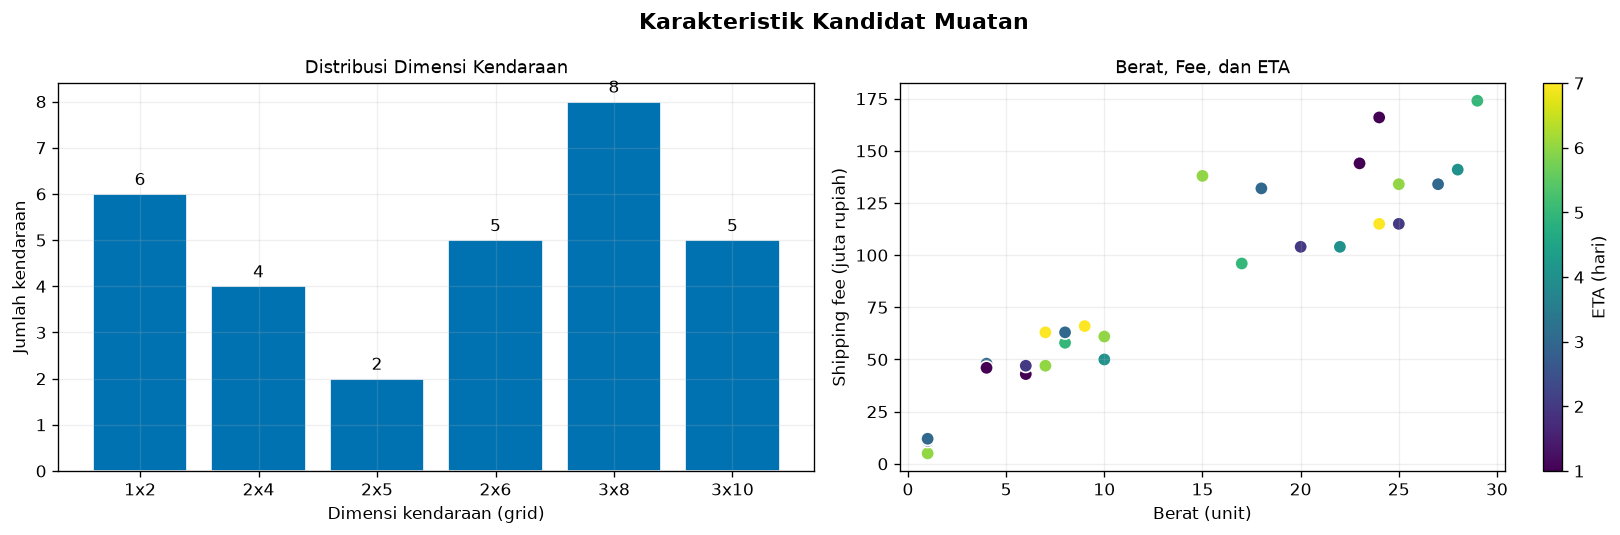

Gambar: output/analysis/01_vehicle_characteristics.png
Fee   -- min: 5 | mean: 78.37 | max: 174
Berat -- min: 1 | mean: 12.73 | max: 29


In [7]:
dimension_counts = Counter(f'{v.width}x{v.length}' for v in main_problem.vehicles)
labels = sorted(dimension_counts, key=lambda label: tuple(int(value) for value in label.split('x')))
counts = [dimension_counts[label] for label in labels]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bars = ax1.bar(labels, counts, color=CFG.COLORS[0], edgecolor='white')
ax1.bar_label(bars, padding=3)
ax1.set(xlabel='Dimensi kendaraan (grid)', ylabel='Jumlah kendaraan', title='Distribusi Dimensi Kendaraan')
scatter = ax2.scatter([v.weight for v in main_problem.vehicles],
                      [v.shipping_fee for v in main_problem.vehicles],
                      c=[v.eta for v in main_problem.vehicles], cmap='viridis', edgecolors='white', s=65)
ax2.set(xlabel='Berat (unit)', ylabel='Shipping fee (juta rupiah)', title='Berat, Fee, dan ETA')
fig.colorbar(scatter, ax=ax2, label='ETA (hari)')
fig.suptitle('Karakteristik Kandidat Muatan', fontsize=13, fontweight='bold')
plt.tight_layout()
show(fig, '01_vehicle_characteristics.png')

print(f'Fee   -- min: {min(v.shipping_fee for v in main_problem.vehicles):g} | mean: {mean(v.shipping_fee for v in main_problem.vehicles):.2f} | max: {max(v.shipping_fee for v in main_problem.vehicles):g}')
print(f'Berat -- min: {min(v.weight for v in main_problem.vehicles):g} | mean: {mean(v.weight for v in main_problem.vehicles):.2f} | max: {max(v.weight for v in main_problem.vehicles):g}')

> ### Insights
> Kendaraan dengan fee tinggi juga menggunakan luas dan kapasitas berat. Rasio fee per sel atau per unit berat dapat membantu interpretasi, tetapi belum menjamin pilihan terbaik karena kendaraan tetap harus dapat disusun tanpa overlap.

---

## Verifikasi Hasil terhadap Input

Seluruh state tersimpan direkonstruksi dari input yang tepat. Evaluator menghitung ulang objective, feasibility, fee, dan upper bound; gambar pasangan run juga diperiksa agar analisis tidak bergantung pada ringkasan yang tidak konsisten.

In [8]:
audit = []
for run, result in pairs:
    original = problems[run.instance]
    problem = eta_problem(original) if run.objective == 'eta' else original
    assert result['algorithm'] == run.algo and result['seed'] == run.seed
    assert result['instance'] == problem.name
    assert result.get('extra', {}).get('objective', 'fee') == run.objective
    for key, value in run.params.items():
        assert result['params'][key] == value
    for stage in ('initial', 'final'):
        state = State.from_dict(problem, result[stage + '_state'])
        evaluation = state.evaluate()
        assert math.isclose(evaluation.objective, result[stage + '_objective'], abs_tol=1e-7)
        if stage == 'final':
            assert evaluation.is_feasible and result['is_feasible']
            assert math.isclose(evaluation.total_fee, result['total_fee'], abs_tol=1e-7)
            if run.objective == 'eta':
                assert math.isclose(shipping_fee_total(original, state.positions), result['extra']['shipping_fee_total'], abs_tol=1e-7)
    bound = upper_bound(problem)
    assert math.isclose(bound, result['upper_bound'], abs_tol=1e-7)
    assert result['final_objective'] <= bound + 1e-7
    if bound:
        assert math.isclose((bound - result['final_objective']) / bound, result['gap_ub'], abs_tol=1e-7)
    path = run.path(CFG.EXPERIMENT_DIR)
    for suffix in ('_initial.png', '_final.png', '_plot.png'):
        assert plt.imread(path.with_name(path.stem + suffix)).size > 0
    audit.append([run.groups[0], run.algo, run.seed, result['extra']['empty_baseline_used']])

print(f'State akhir tervalidasi : {len(audit)}')
print(f'Baseline kosong        : {sum(row[3] for row in audit)}')
insights(f'Seluruh {len(audit)} state akhir lolos evaluasi ulang. '
         'Validitas fisik diperiksa dari penempatan, bukan diasumsikan dari angka objective akhir.')

State akhir tervalidasi : 39
Baseline kosong        : 0


> ### Insights
> Seluruh 39 state akhir lolos evaluasi ulang. Validitas fisik diperiksa dari penempatan, bukan diasumsikan dari angka objective akhir.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Protokol dan Hasil Eksperimen <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Setiap konfigurasi menggunakan tiga seed. Dua sweep GA dilaksanakan terpisah: populasi menjadi kontrol saat generasi divariasikan, kemudian generasi menjadi kontrol saat populasi divariasikan. Parameter lain dipertahankan.

---

## Cakupan Eksperimen

Daftar berikut memisahkan eksperimen wajib dan bonus. Pengulangan kontrol GA memenuhi pelaksanaan kedua sweep, tetapi pasangan parameter dan seed yang identik tidak dihitung sebagai sampel independen tambahan pada perbandingan kualitas.

In [9]:
group_counts = Counter(run.groups[0] for run in plan)
table(['Grup', 'Eksperimen', 'Run', 'Kategori'],
      [[group, CFG.GROUP_NAMES[group], count,
        'Wajib' if any(run.required for run in plan if run.groups[0] == group) else 'Bonus']
       for group, count in group_counts.items()])

print(f'Total : {len(plan)} run, termasuk {sum(run.required for run in plan)} run wajib')

Grup,Eksperimen,Run,Kategori
hc,Steepest Ascent,3,Wajib
sa,Simulated Annealing,3,Wajib
ga_iter,GA: Variasi Generasi,9,Wajib
ga_pop,GA: Variasi Populasi,9,Wajib
hc_variants,Varian Hill-Climbing,9,Bonus
eta,Objective ETA,3,Bonus
multi,Multi-kapal,3,Bonus


Total : 39 run, termasuk 24 run wajib


---

## Hasil Setiap Run

Tabel menampilkan hasil per seed, bukan hanya run terbaik. Fee asli dipisahkan dari objective ETA, sedangkan durasi berasal dari proses pencarian yang dicatat dalam JSON. Mengulang notebook hanya menghitung tabel dan menggambar hasil, tidak menghasilkan waktu search baru.

In [10]:
for group in group_counts:
    display(Markdown('### ' + CFG.GROUP_NAMES[group]))
    rows = []
    for run, result in of(group):
        params = result['params']
        setup = f"pop={params['population']}, gen={params['iterations']}" if run.algo == 'ga' else CFG.ALGO_NAMES[run.algo]
        revenue = result['extra'].get('shipping_fee_total', result['total_fee'])
        rows.append([run.seed, setup, f"{result['initial_objective']:.2f}",
                     f"{result['final_objective']:.2f}", f'{revenue:.2f}', result['is_feasible'],
                     result['iterations'], result['evaluations'], f"{result['duration_s']:.3f}"])
    table(['Seed', 'Konfigurasi', 'Obj awal', 'Obj akhir', 'Fee asli', 'Feasible', 'Iterasi', 'Evaluasi', 'Durasi (s)'], rows)

### Steepest Ascent

Seed,Konfigurasi,Obj awal,Obj akhir,Fee asli,Feasible,Iterasi,Evaluasi,Durasi (s)
1,Steepest Ascent,-21226.00,982.00,982.00,True,16,208453,1.251
2,Steepest Ascent,-50553.00,978.00,978.00,True,20,258032,1.549
3,Steepest Ascent,-28402.00,902.00,902.00,True,17,221239,1.327


### Simulated Annealing

Seed,Konfigurasi,Obj awal,Obj akhir,Fee asli,Feasible,Iterasi,Evaluasi,Durasi (s)
1,Simulated Annealing,-21226.00,964.00,964.00,True,100000,1190686,8.435
2,Simulated Annealing,-50553.00,973.00,973.00,True,100000,1148994,8.488
3,Simulated Annealing,-28402.00,962.00,962.00,True,100000,1070792,10.121


### GA: Variasi Generasi

...

Seed,Konfigurasi,Obj awal,Obj akhir,Fee asli,Feasible,Iterasi,Evaluasi,Durasi (s)
1,Stochastic HC,-21226.00,778.00,778.00,True,36486,36487,0.405
2,Stochastic HC,-50553.00,876.00,876.00,True,32510,32511,0.365
3,Stochastic HC,-28402.00,771.00,771.00,True,24504,24505,0.277
1,Sideways Move,-21226.00,982.00,982.00,True,116,1429123,10.700
2,Sideways Move,-50553.00,978.00,978.00,True,120,1478702,10.127
3,Sideways Move,-28402.00,960.00,960.00,True,118,1456575,10.743
1,Random Restart,-21226.00,982.00,982.00,True,203,2507634,16.864
2,Random Restart,-50553.00,993.00,993.00,True,205,2534283,16.876
3,Random Restart,-28402.00,946.00,946.00,True,207,2561237,16.493


### Objective ETA

Seed,Konfigurasi,Obj awal,Obj akhir,Fee asli,Feasible,Iterasi,Evaluasi,Durasi (s)
1,Simulated Annealing,-30496.84,1293.30,984.00,True,100000,1011879,8.455
2,Simulated Annealing,-72463.87,1223.58,941.00,True,100000,1119216,8.808
3,Simulated Annealing,-40726.81,1228.80,941.00,True,100000,1043427,8.883


### Multi-kapal

Seed,Konfigurasi,Obj awal,Obj akhir,Fee asli,Feasible,Iterasi,Evaluasi,Durasi (s)
1,Steepest Ascent,-59430.00,1170.00,1170.00,True,27,569887,4.060
2,Steepest Ascent,-37965.00,1072.00,1072.00,True,23,489470,3.666
3,Steepest Ascent,-76448.00,1078.00,1078.00,True,28,590444,4.156


> ### Insights
> Nilai akhir merupakan incumbent feasible, sedangkan kurva berikut tetap memperlihatkan objective berjalan atau maksimum populasi. Perbedaan tersebut penting ketika search masih berada pada susunan berpenalti.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Hill-Climbing <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Hill-Climbing memperbaiki konfigurasi melalui neighborhood move, swap, dan rotate. Empat varian dibedakan oleh pemilihan neighbor, penerimaan nilai setara, atau pengulangan initial state.

---

## Varian dan Penghentian

Steepest Ascent memeriksa seluruh neighborhood; Stochastic memeriksa proposal random; Sideways menerima perpindahan bernilai setara sampai batas total; Random Restart menjalankan Steepest kembali dari initial acak baru. Jumlah evaluasi karena itu tidak dapat disamakan dengan jumlah iterasi.

In [11]:
hc_pairs = of('hc') + of('hc_variants')
hc_rows = []
for run, result in hc_pairs:
    params, extra = result['params'], result['extra']
    limit = (f"sideways={params['max_sideways']}" if run.algo == 'sideways' else
             f"restart={params['max_restart']}" if run.algo == 'random_restart' else
             f"no_improve={params['max_no_improve']}" if run.algo == 'stochastic' else
             f"iter_max={params['max_iterations']}")
    detail = ', '.join(str(value) for value in extra['iters_per_restart']) if run.algo == 'random_restart' else str(extra.get('sideways_moves', '-'))
    stop = ', '.join(sorted(set(extra['stop_reasons']))) if run.algo == 'random_restart' else extra['stop_reason']
    hc_rows.append([CFG.ALGO_NAMES[run.algo], run.seed, limit,
                    extra.get('restarts', '-'), detail, stop])
table(['Varian', 'Seed', 'Batas', 'Restart', 'Sideways / iterasi tiap percobaan', 'Stop reason'], hc_rows)

Varian,Seed,Batas,Restart,Sideways / iterasi tiap percobaan,Stop reason
Steepest Ascent,1,iter_max=10000,-,-,local_optimum
Steepest Ascent,2,iter_max=10000,-,-,local_optimum
Steepest Ascent,3,iter_max=10000,-,-,local_optimum
Stochastic HC,1,no_improve=20000,-,-,max_no_improve
Stochastic HC,2,no_improve=20000,-,-,max_no_improve
Stochastic HC,3,no_improve=20000,-,-,max_no_improve
Sideways Move,1,sideways=100,-,100,max_sideways
Sideways Move,2,sideways=100,-,100,max_sideways
Sideways Move,3,sideways=100,-,100,max_sideways
Random Restart,1,restart=10,10,"16, 14, 20, 17, 16, 15, 17, 17, 23, 16, 22",local_optimum


---

## Kurva Konvergensi

Satu baris gambar digunakan untuk satu varian dan tiga seed. Nilai negatif tetap terlihat untuk memperlihatkan pemulihan dari initial infeasible, sementara garis incumbent menunjukkan muatan valid terbaik yang sudah ditemukan.

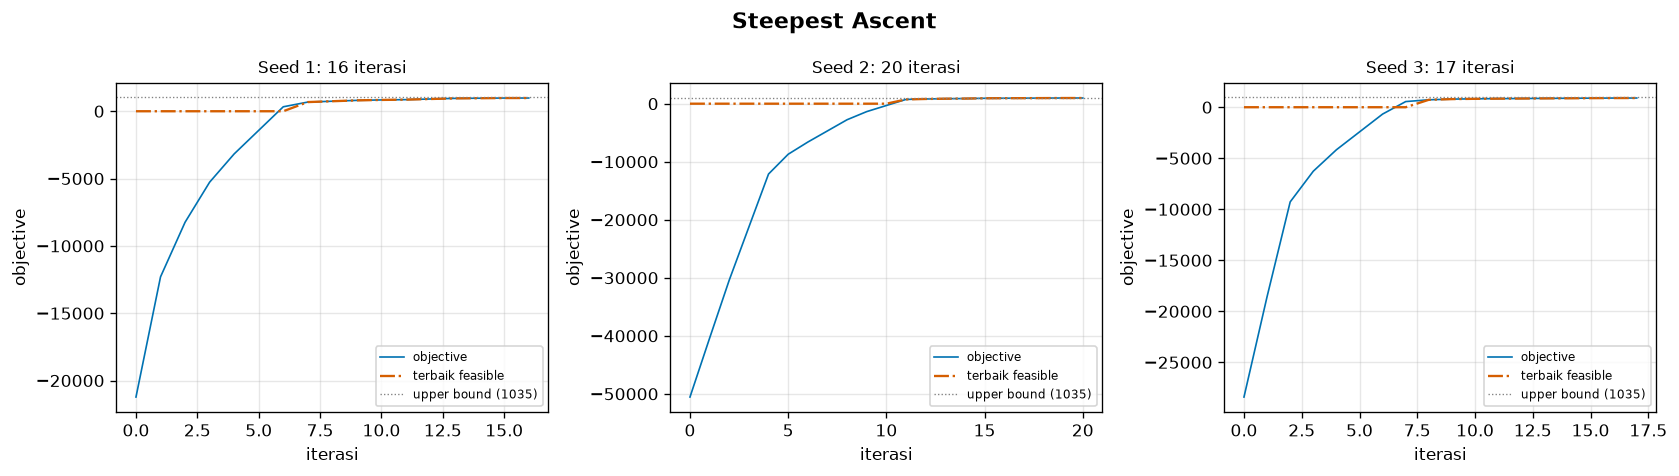

Gambar: output/analysis/03_hc_steepest.png


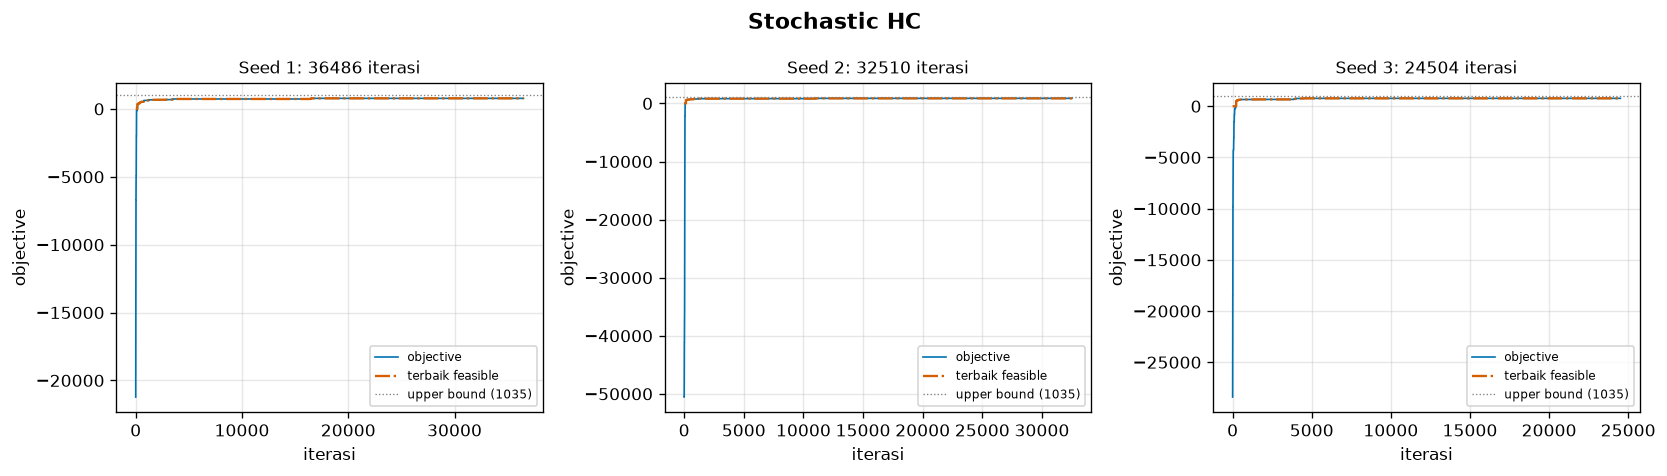

Gambar: output/analysis/03_hc_stochastic.png


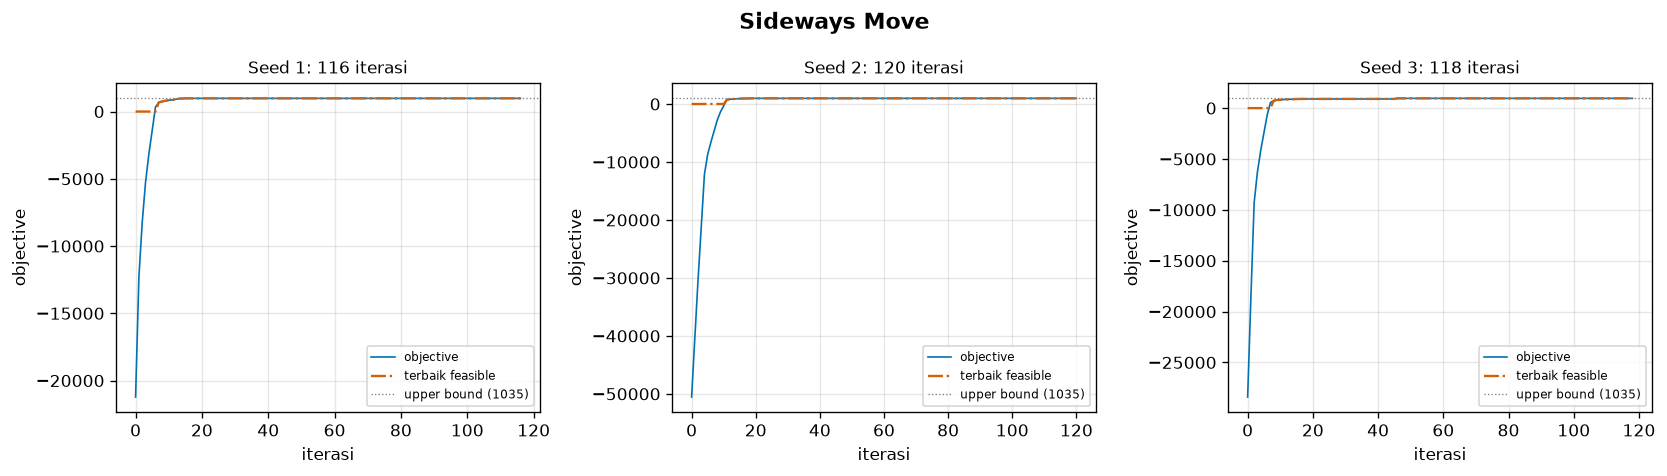

Gambar: output/analysis/03_hc_sideways.png


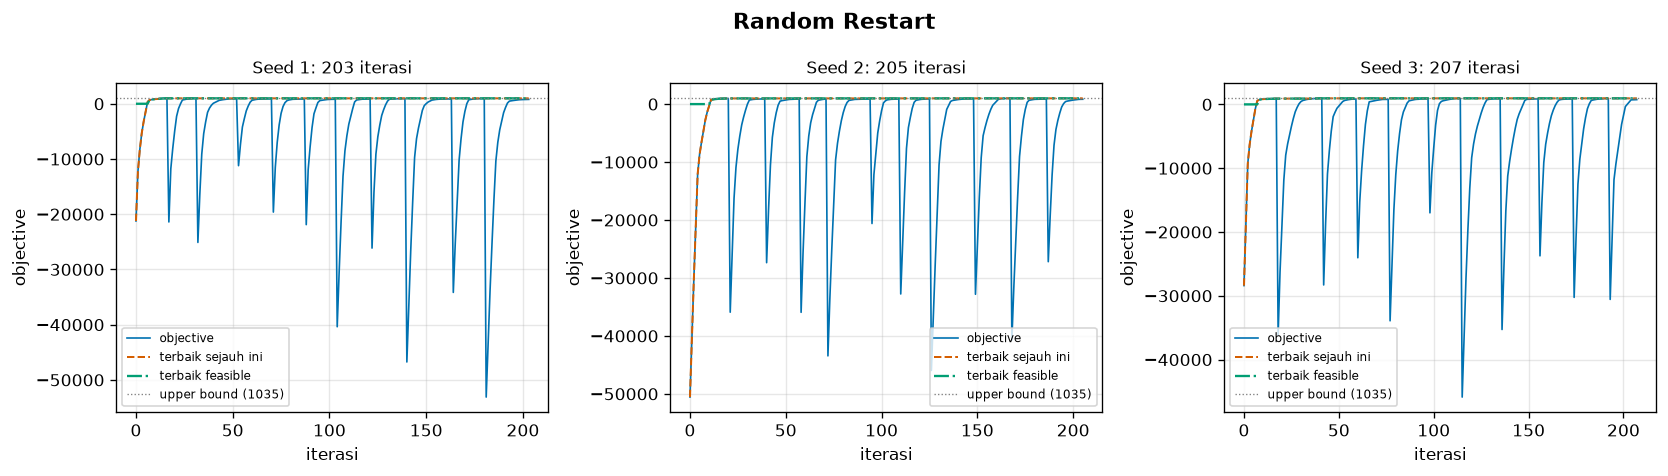

Gambar: output/analysis/03_hc_random_restart.png


> ### Insights
> Mean objective akhir: Steepest Ascent = 954.00; Stochastic HC = 808.33; Sideways Move = 973.33; Random Restart = 973.67. Hasil antarvarian dibaca bersama biaya evaluasi dan parameter penghentiannya.

In [12]:
hc_algorithms = ('steepest', 'stochastic', 'sideways', 'random_restart')
for algo in hc_algorithms:
    selected = sorted([(run, result) for run, result in hc_pairs if run.algo == algo], key=lambda pair: pair[0].seed)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (run, result) in zip(axes, selected):
        plot_objective(ax, result)
        ax.set_title(f"Seed {run.seed}: {result['iterations']} iterasi", fontsize=10)
    fig.suptitle(CFG.ALGO_NAMES[algo], fontsize=13, fontweight='bold')
    plt.tight_layout()
    show(fig, f'03_hc_{algo}.png')

hc_means = {algo: mean(result['final_objective'] for run, result in hc_pairs if run.algo == algo) for algo in hc_algorithms}
insights('Mean objective akhir: ' + '; '.join(f'{CFG.ALGO_NAMES[algo]} = {value:.2f}' for algo, value in hc_means.items()) + '. '
         'Hasil antarvarian dibaca bersama biaya evaluasi dan parameter penghentiannya.')

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Simulated Annealing <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Simulated Annealing dapat menerima perpindahan yang memperburuk objective dengan peluang `exp(delta/T)`. Suhu diturunkan secara geometris; T0 berasal dari sampel neighbor awal. Mekanisme ini memungkinkan pencarian meninggalkan konfigurasi yang tidak dapat dilewati HC biasa.

---

## Objective dan Peluang Penerimaan

Setiap seed ditampilkan dengan dua panel: objective terhadap iterasi dan peluang menerima langkah dengan delta negatif. Peluang bukan persentase keberhasilan; incumbent feasible tetap menjadi dasar solusi akhir.

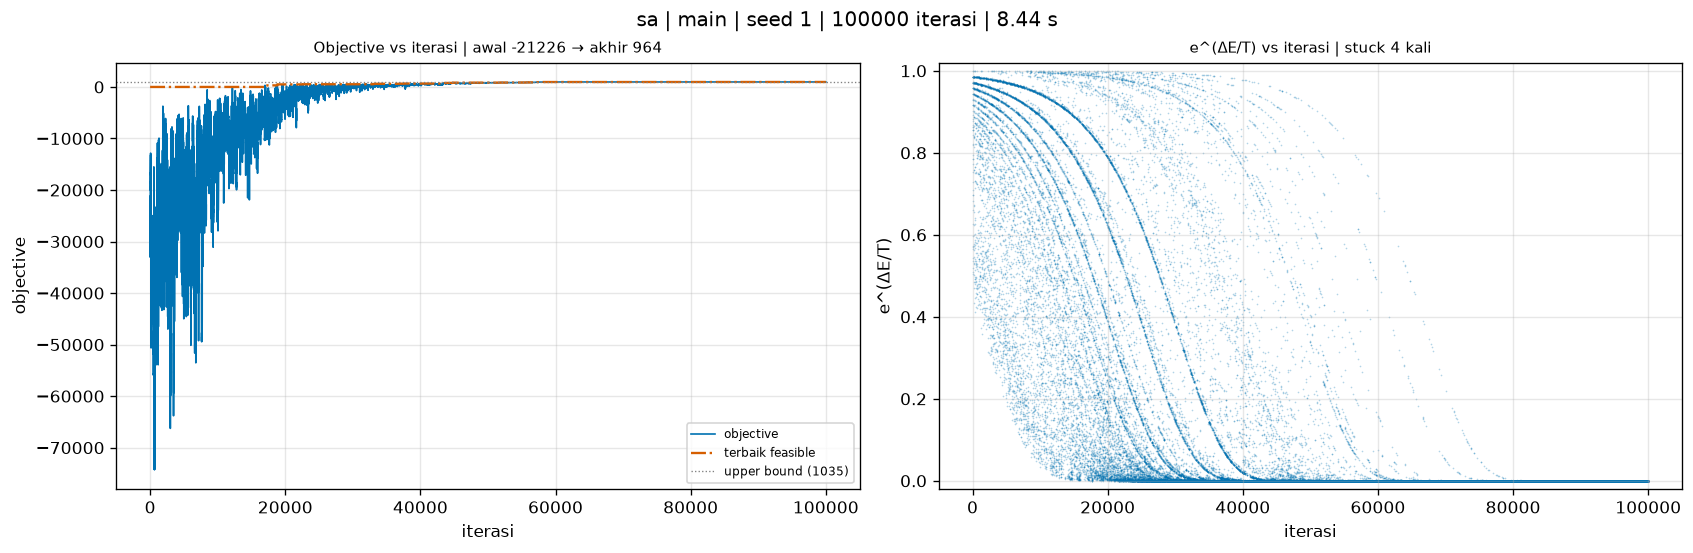

Gambar: output/analysis/04_sa_seed1.png


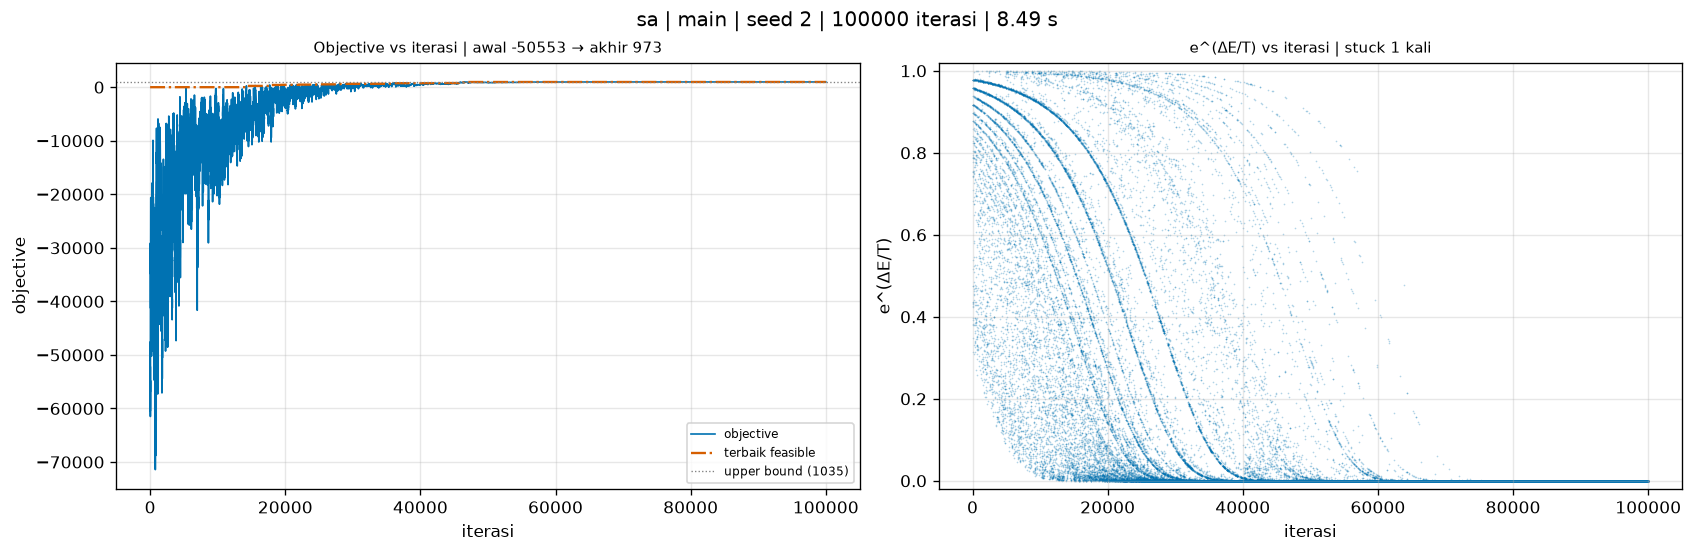

Gambar: output/analysis/04_sa_seed2.png


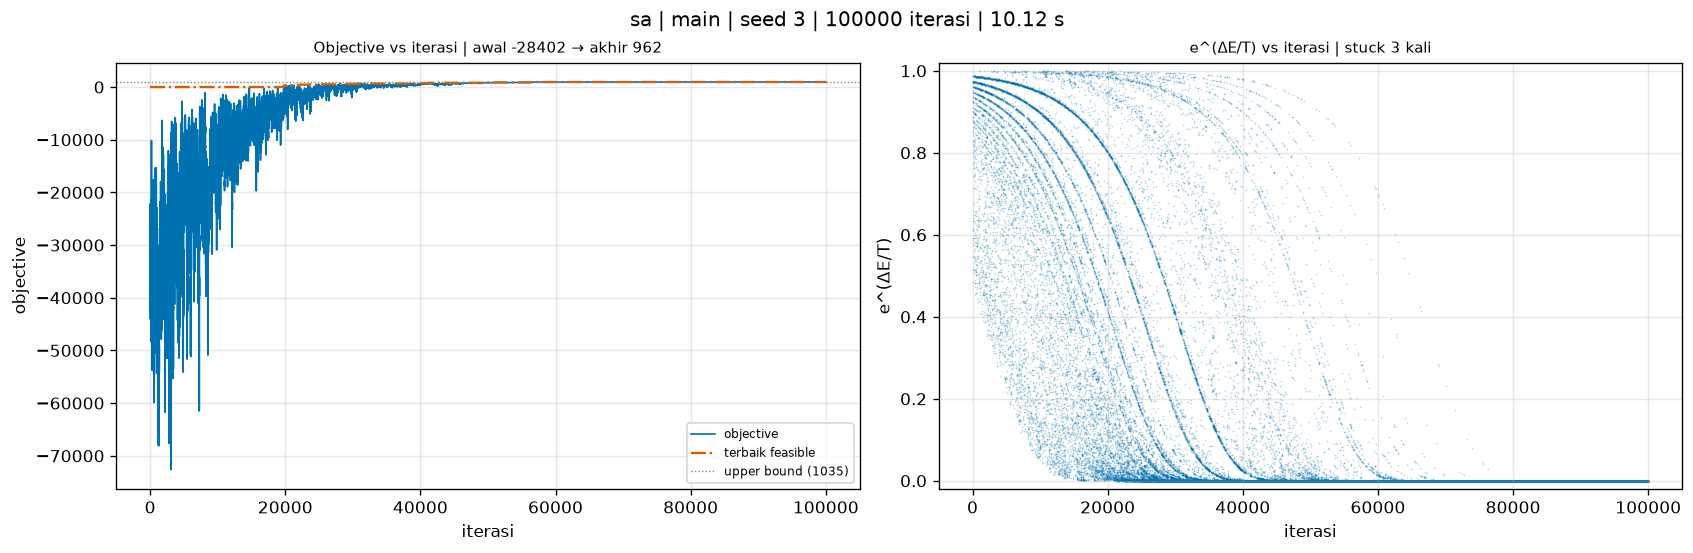

Gambar: output/analysis/04_sa_seed3.png


In [13]:
sa_results = [result for run, result in of('sa')]
for run, result in of('sa'):
    fig = plot_run(result)
    fig.set_size_inches(14, 4.5)
    show(fig, f'04_sa_seed{run.seed}.png')

---

## Stuck dan Stagnasi

Local optimum dikonfirmasi melalui pemeriksaan neighborhood pada checkpoint. Episode dihitung sekali untuk rangkaian checkpoint local-optimum yang berurutan. Stagnasi best-so-far dicatat terpisah, karena tidak adanya rekor baru belum membuktikan bahwa semua neighbor lebih buruk.

In [14]:
table(['Seed', 'T0', 'Alpha', 'Interval cek', 'Episode stuck', 'Stagnasi', 'Evaluasi konfirmasi'],
      [[r['seed'], f"{r['extra']['t0']:.2f}", f"{r['extra']['alpha']:.6f}",
        r['params']['stuck_window'], r['extra']['stuck_count'], r['extra']['stagnation_count'],
        r['extra']['confirmation_evaluations']] for r in sa_results])

insights(f"Mean objective SA = {mean(r['final_objective'] for r in sa_results):.2f}; "
         f"mean episode stuck teramati = {mean(r['extra']['stuck_count'] for r in sa_results):.2f}. "
         'Kunjungan di antara checkpoint dapat tidak terdeteksi. Biaya konfirmasi sudah termasuk jumlah evaluasi dan durasi SA.')

Seed,T0,Alpha,Interval cek,Episode stuck,Stagnasi,Evaluasi konfirmasi
1,12153.52,0.999860,500,4,182,1090585
2,8142.36,0.999864,500,1,185,1048893
3,13226.03,0.999859,500,3,179,970691


> ### Insights
> Mean objective SA = 966.33; mean episode stuck teramati = 2.67. Kunjungan di antara checkpoint dapat tidak terdeteksi. Biaya konfirmasi sudah termasuk jumlah evaluasi dan durasi SA.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Genetic Algorithm <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Genetic Algorithm mempertahankan populasi konfigurasi kendaraan. Seleksi roulette memakai fitness positif hasil windowing; crossover satu titik, mutasi neighbor, dan elitism membentuk generasi berikutnya. Karena koordinat antarkendaraan saling bergantung, offspring crossover dapat kembali overlap.

---

## Kontrol Populasi, Variasi Generasi

Populasi ditahan pada nilai kontrol dan generasi divariasikan. Tiap gambar memuat tiga seed untuk satu konfigurasi agar maksimum serta rata-rata populasi tetap terbaca.

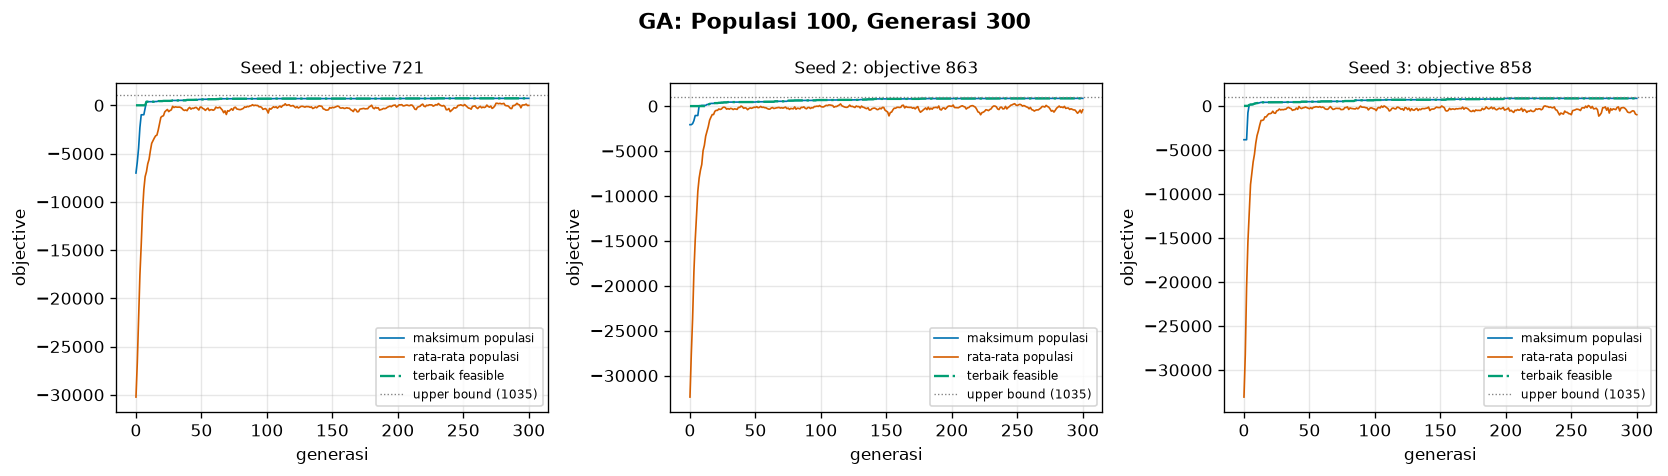

Gambar: output/analysis/05_ga_generations_300.png


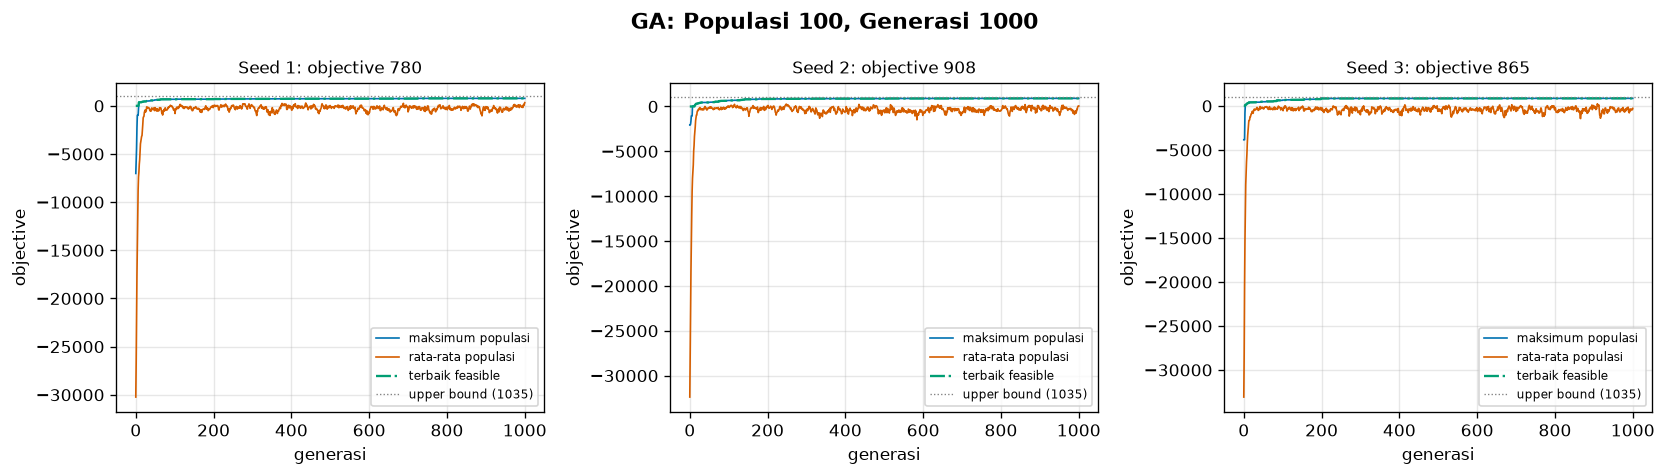

Gambar: output/analysis/05_ga_generations_1000.png


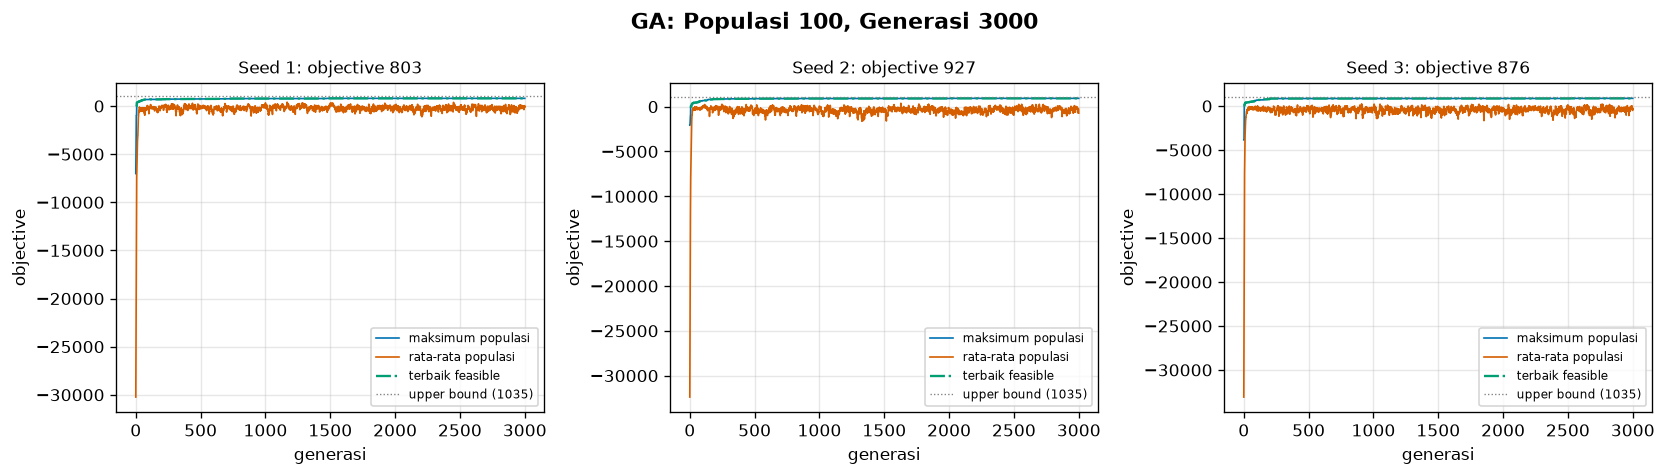

Gambar: output/analysis/05_ga_generations_3000.png


In [15]:
ga_iter_pairs = of('ga_iter')
for generations in sorted({result['params']['iterations'] for run, result in ga_iter_pairs}):
    selected = [(run, result) for run, result in ga_iter_pairs if result['params']['iterations'] == generations]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (run, result) in zip(axes, selected):
        plot_objective(ax, result)
        ax.set_title(f"Seed {run.seed}: objective {result['final_objective']:g}", fontsize=10)
    population = selected[0][1]['params']['population']
    fig.suptitle(f'GA: Populasi {population}, Generasi {generations}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    show(fig, f'05_ga_generations_{generations}.png')

> ### Insights
> Generasi tambahan memperpanjang kesempatan eksplorasi pada ukuran populasi yang sama. Jarak antara maksimum dan rata-rata populasi memperlihatkan bahwa kualitas individu terbaik tidak mewakili seluruh offspring.

---

## Kontrol Generasi, Variasi Populasi

Generasi ditahan pada nilai kontrol dan populasi divariasikan. Kontrol dijalankan lagi untuk sweep ini, bukan memakai satu pelaksanaan yang sama dengan sweep sebelumnya.

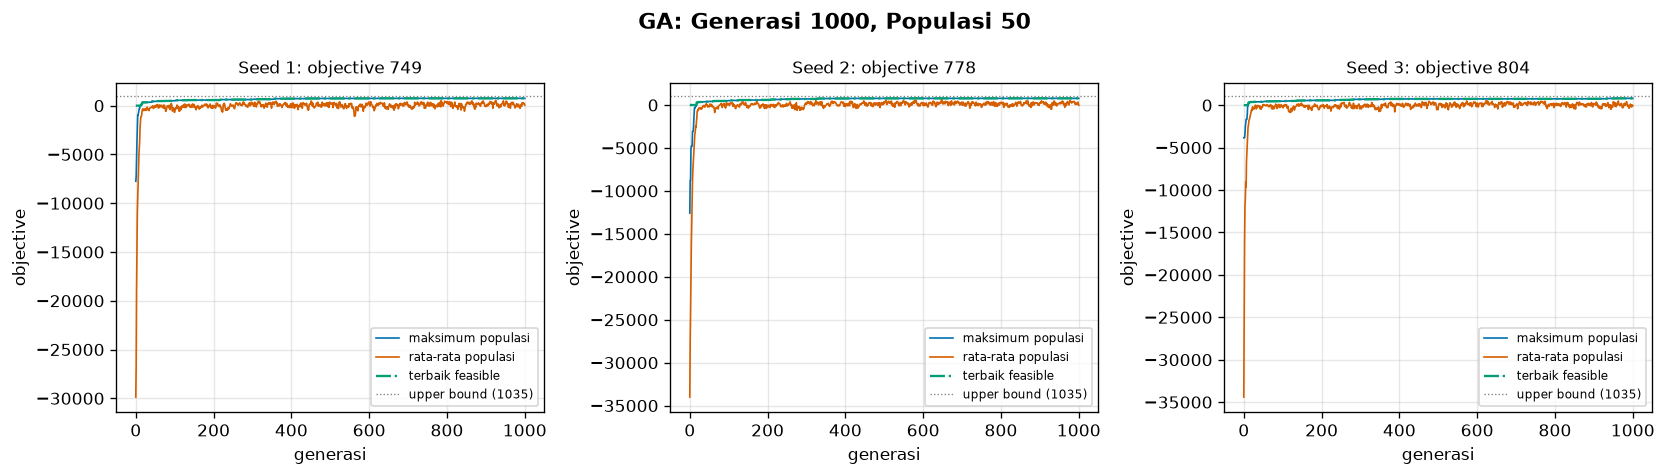

Gambar: output/analysis/06_ga_population_50.png


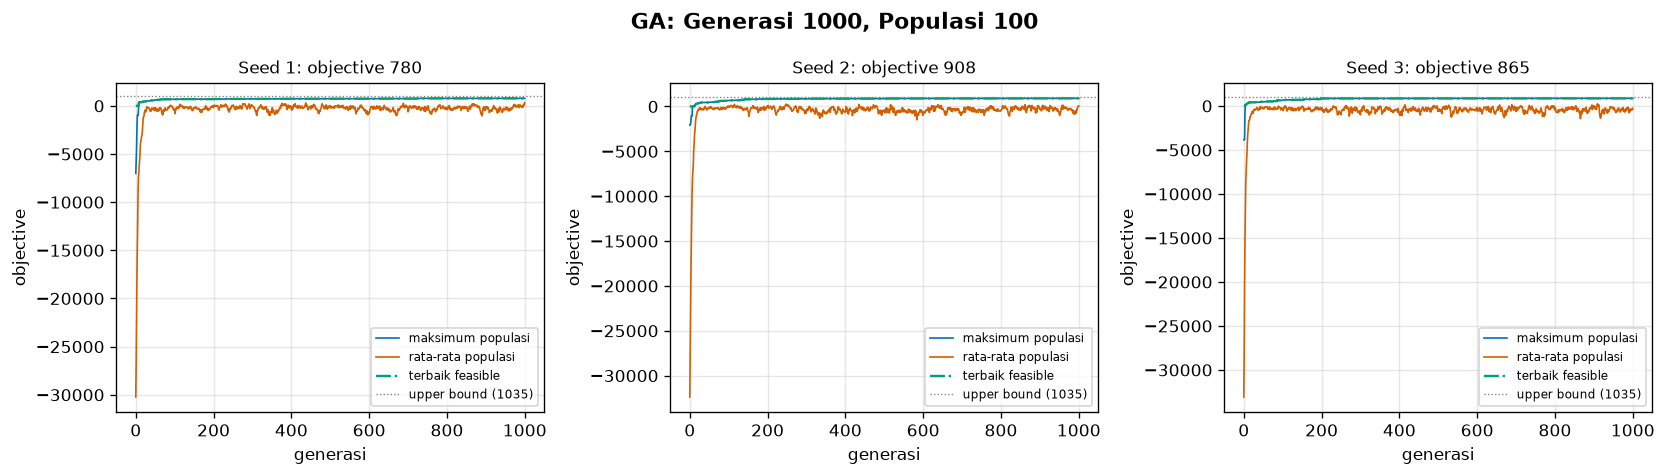

Gambar: output/analysis/06_ga_population_100.png


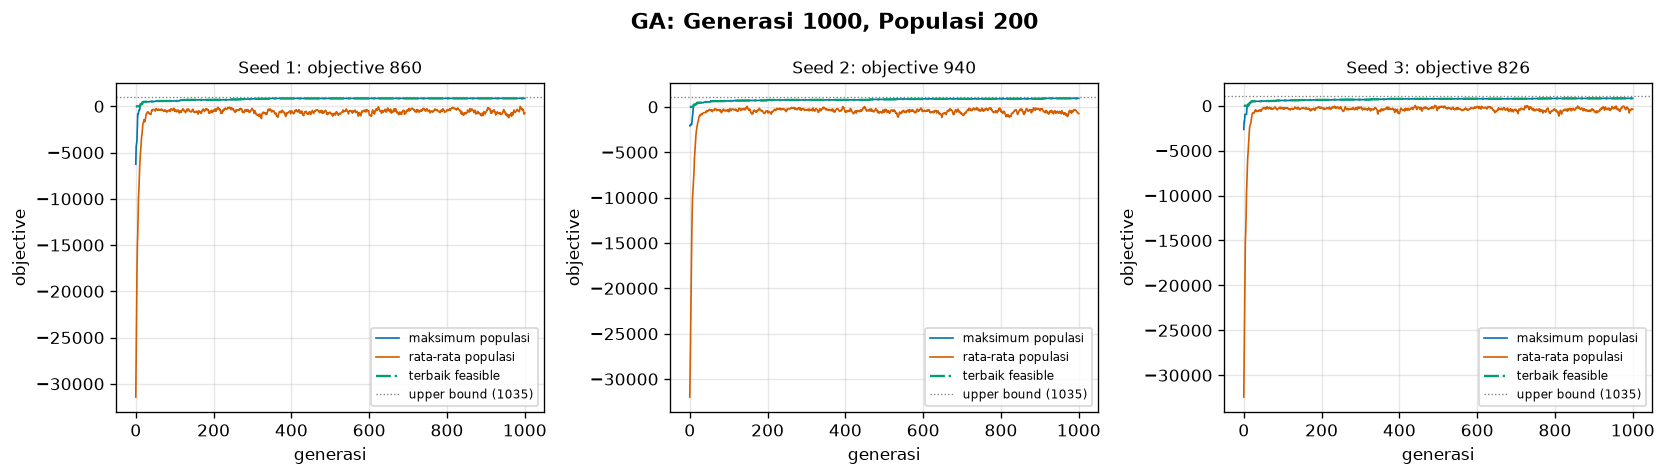

Gambar: output/analysis/06_ga_population_200.png


In [16]:
ga_pop_pairs = of('ga_pop')
for population in sorted({result['params']['population'] for run, result in ga_pop_pairs}):
    selected = [(run, result) for run, result in ga_pop_pairs if result['params']['population'] == population]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (run, result) in zip(axes, selected):
        plot_objective(ax, result)
        ax.set_title(f"Seed {run.seed}: objective {result['final_objective']:g}", fontsize=10)
    generations = selected[0][1]['params']['iterations']
    fig.suptitle(f'GA: Generasi {generations}, Populasi {population}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    show(fig, f'06_ga_population_{population}.png')

---

## Pengaruh Budget Pencarian

Mean dan simpangan baku tiap konfigurasi dibandingkan bersama durasi serta evaluasi. Kenaikan populasi maupun generasi menambah budget komputasi, sehingga perubahan kualitas tidak dibaca terpisah dari biayanya.

In [17]:
ga_budget_rows = []
for group, key in (('ga_iter', 'iterations'), ('ga_pop', 'population')):
    members = of(group)
    for value in sorted({result['params'][key] for run, result in members}):
        selected = [result for run, result in members if result['params'][key] == value]
        ga_budget_rows.append([group, value, mean(r['final_objective'] for r in selected),
                               stdev(r['final_objective'] for r in selected),
                               mean(r['duration_s'] for r in selected), mean(r['evaluations'] for r in selected)])
table(['Sweep', 'Parameter', 'Obj mean', 'Obj std', 'Durasi mean (s)', 'Evaluasi mean'],
      [[*row[:2], *(f'{value:.3f}' for value in row[2:])] for row in ga_budget_rows])

for group in ('ga_iter', 'ga_pop'):
    rows = [row for row in ga_budget_rows if row[0] == group]
    low, high = rows[0], rows[-1]
    insights(f'{CFG.GROUP_NAMES[group]}: parameter {low[1]} ke {high[1]} memberi perubahan mean objective '
             f'{high[2] - low[2]:+.2f}, durasi {high[4] - low[4]:+.3f} s, dan evaluasi {high[5] - low[5]:+.0f}. '
             'Hasil tersebut berlaku pada konfigurasi dan seed yang dibandingkan.')

Sweep,Parameter,Obj mean,Obj std,Durasi mean (s),Evaluasi mean
ga_iter,300,814.000,80.579,0.268,29500.000
ga_iter,1000,851.000,65.138,0.805,98100.000
ga_iter,3000,868.667,62.324,2.414,294100.000
ga_pop,50,777.000,27.514,0.338,48050.000
ga_pop,100,851.000,65.138,0.835,98100.000
ga_pop,200,875.333,58.526,2.002,198200.000


> ### Insights
> GA: Variasi Generasi: parameter 300 ke 3000 memberi perubahan mean objective +54.67, durasi +2.146 s, dan evaluasi +264600. Hasil tersebut berlaku pada konfigurasi dan seed yang dibandingkan.

> ### Insights
> GA: Variasi Populasi: parameter 50 ke 200 memberi perubahan mean objective +98.33, durasi +1.665 s, dan evaluasi +150150. Hasil tersebut berlaku pada konfigurasi dan seed yang dibandingkan.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Perbandingan Algoritma <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Perbandingan memakai objective fee pada instance utama. GA diwakili konfigurasi dengan mean tertinggi dari sweep. Pengulangan kontrol dengan seed sama dihitung sekali agar ringkasan tidak memperlakukan keluaran deterministik sebagai sampel baru.

---

## Kualitas, Durasi, dan Konsistensi

Tabel merangkum seluruh seed, sementara box plot menampilkan sebaran objective akhir dan titik setiap run. Durasi merupakan waktu pencarian tersimpan, termasuk monitoring neighborhood pada SA.

Algoritma,n,Best,Mean,Std,Durasi (s),Evaluasi,Gap UB (%)
steepest,3,982.000,954.000,45.078,1.376,229241.333,7.826
sa,3,973.000,966.333,5.859,9.015,1136824.000,6.634
stochastic,3,876.000,808.333,58.705,0.349,31167.667,21.900
sideways,3,982.000,973.333,11.719,10.523,1454800.000,5.958
random_restart,3,993.000,973.667,24.583,16.745,2534384.667,5.926
"ga (pop 200, iter 1000) - terbaik",3,940.000,875.333,58.526,2.002,198200.000,15.427


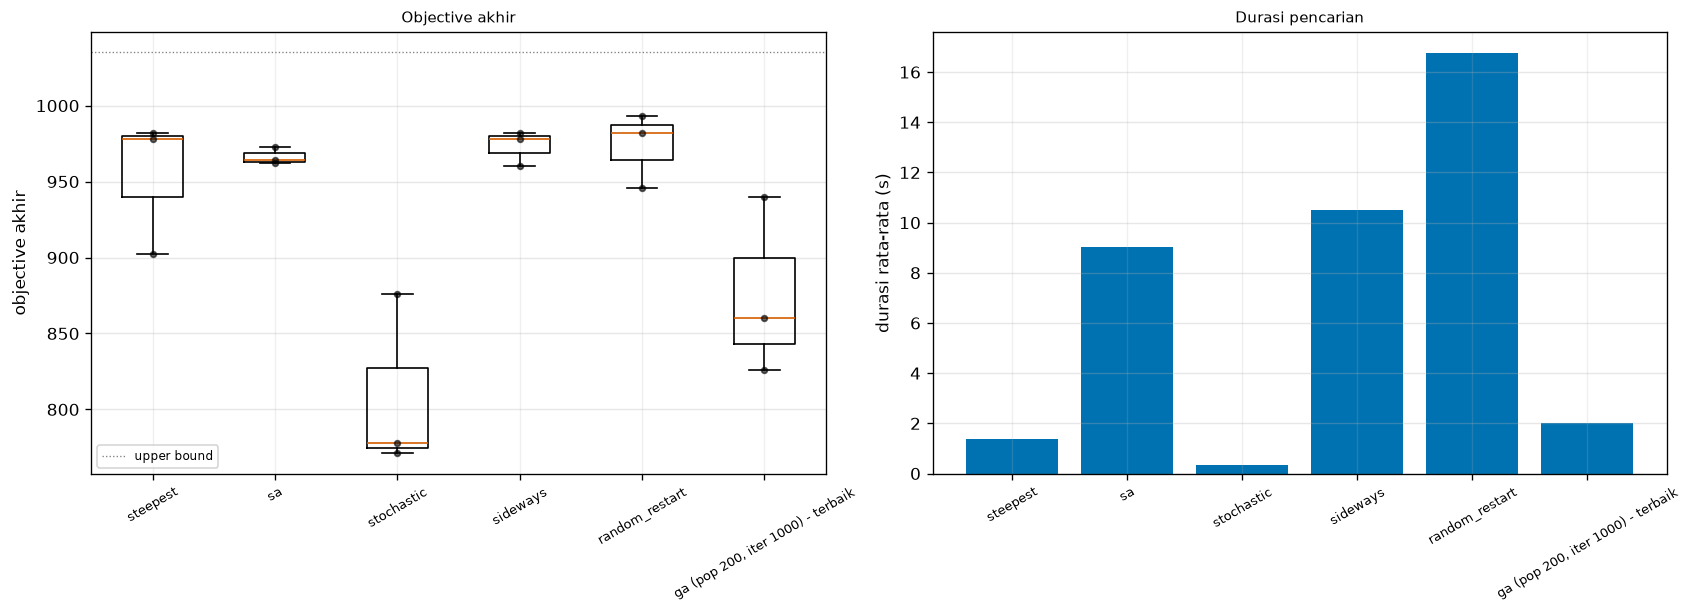

Gambar: output/analysis/07_algorithm_comparison.png


> ### Insights
> Mean kualitas tertinggi: random_restart (973.67); durasi mean terendah: stochastic (0.349 s); simpangan baku terendah: sa (5.86). Ketiga ukuran menjawab pertanyaan berbeda; variansi rendah pada objective rendah tidak menunjukkan solusi terbaik.

In [18]:
compare = comparison_groups(pairs)
comparison = []
for label, results in compare.items():
    finals = [result['final_objective'] for result in results]
    comparison.append([label, len(results), max(finals), mean(finals), stdev(finals),
                       mean(r['duration_s'] for r in results), mean(r['evaluations'] for r in results),
                       100 * mean(r['gap_ub'] for r in results)])
table(['Algoritma', 'n', 'Best', 'Mean', 'Std', 'Durasi (s)', 'Evaluasi', 'Gap UB (%)'],
      [[row[0], row[1], *(f'{value:.3f}' for value in row[2:])] for row in comparison])

labels = {id(result): label for label, results in compare.items() for result in results}
fig = plot_summary([result for results in compare.values() for result in results], group=lambda result: labels[id(result)])
fig.set_size_inches(14, 5)
show(fig, '07_algorithm_comparison.png')

best_quality = max(comparison, key=lambda row: row[3])
fastest = min(comparison, key=lambda row: row[5])
consistent = min(comparison, key=lambda row: row[4])
insights(f'Mean kualitas tertinggi: {best_quality[0]} ({best_quality[3]:.2f}); '
         f'durasi mean terendah: {fastest[0]} ({fastest[5]:.3f} s); '
         f'simpangan baku terendah: {consistent[0]} ({consistent[4]:.2f}). '
         'Ketiga ukuran menjawab pertanyaan berbeda; variansi rendah pada objective rendah tidak menunjukkan solusi terbaik.')

---

## Konvergensi terhadap Evaluasi Aktual

Sumbu horizontal menggunakan hitungan kumulatif `history.evaluations`, bukan interpolasi dari total evaluasi. Kurva memilih satu run terbaik tiap algoritma dan menampilkan incumbent feasible dengan garis bertangga.

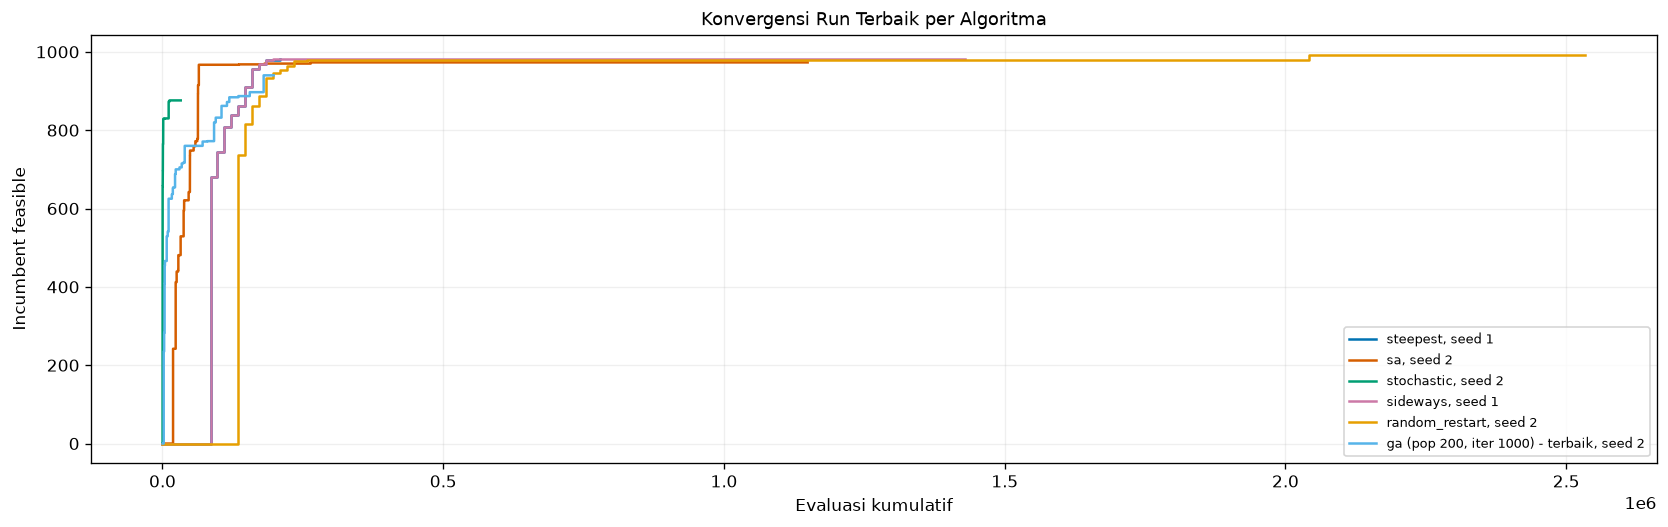

Gambar: output/analysis/08_actual_evaluations.png


In [19]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for label, results in compare.items():
    result = max(results, key=lambda item: item['final_objective'])
    x = result['history']['evaluations']
    y = result['history']['best_feasible']
    assert len(x) == len(y) == result['iterations'] + 1
    assert x[-1] == result['evaluations']
    assert all(right >= left for left, right in zip(x, x[1:]))
    ax.step(x, y, where='post', label=f"{label}, seed {result['seed']}")
ax.set(xlabel='Evaluasi kumulatif', ylabel='Incumbent feasible', title='Konvergensi Run Terbaik per Algoritma')
ax.legend(fontsize=8)
plt.tight_layout()
show(fig, '08_actual_evaluations.png')

> ### Insights
> Satu delta probe tidak selalu berbiaya sama dengan penilaian individu GA. Kurva evaluasi menjelaskan pekerjaan algoritma, sedangkan durasi tetap diperlukan untuk membandingkan biaya pada mesin yang digunakan.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Visualisasi Penataan Kendaraan <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

State awal dan akhir dari run terbaik setiap algoritma ditampilkan berpasangan. Gambar diambil dari artefak run yang sama, sehingga visualisasi tidak menggunakan pencarian baru dengan hasil berbeda.

---

## Initial State dan Final State

Warna dan id kendaraan dipertahankan antargambar. Arsir merah serta garis putus-putus menunjukkan pelanggaran pada initial state, sedangkan panel luar kapal memperlihatkan kandidat yang tidak diangkut. Judul setiap pasangan mencantumkan seed dan objective akhir.

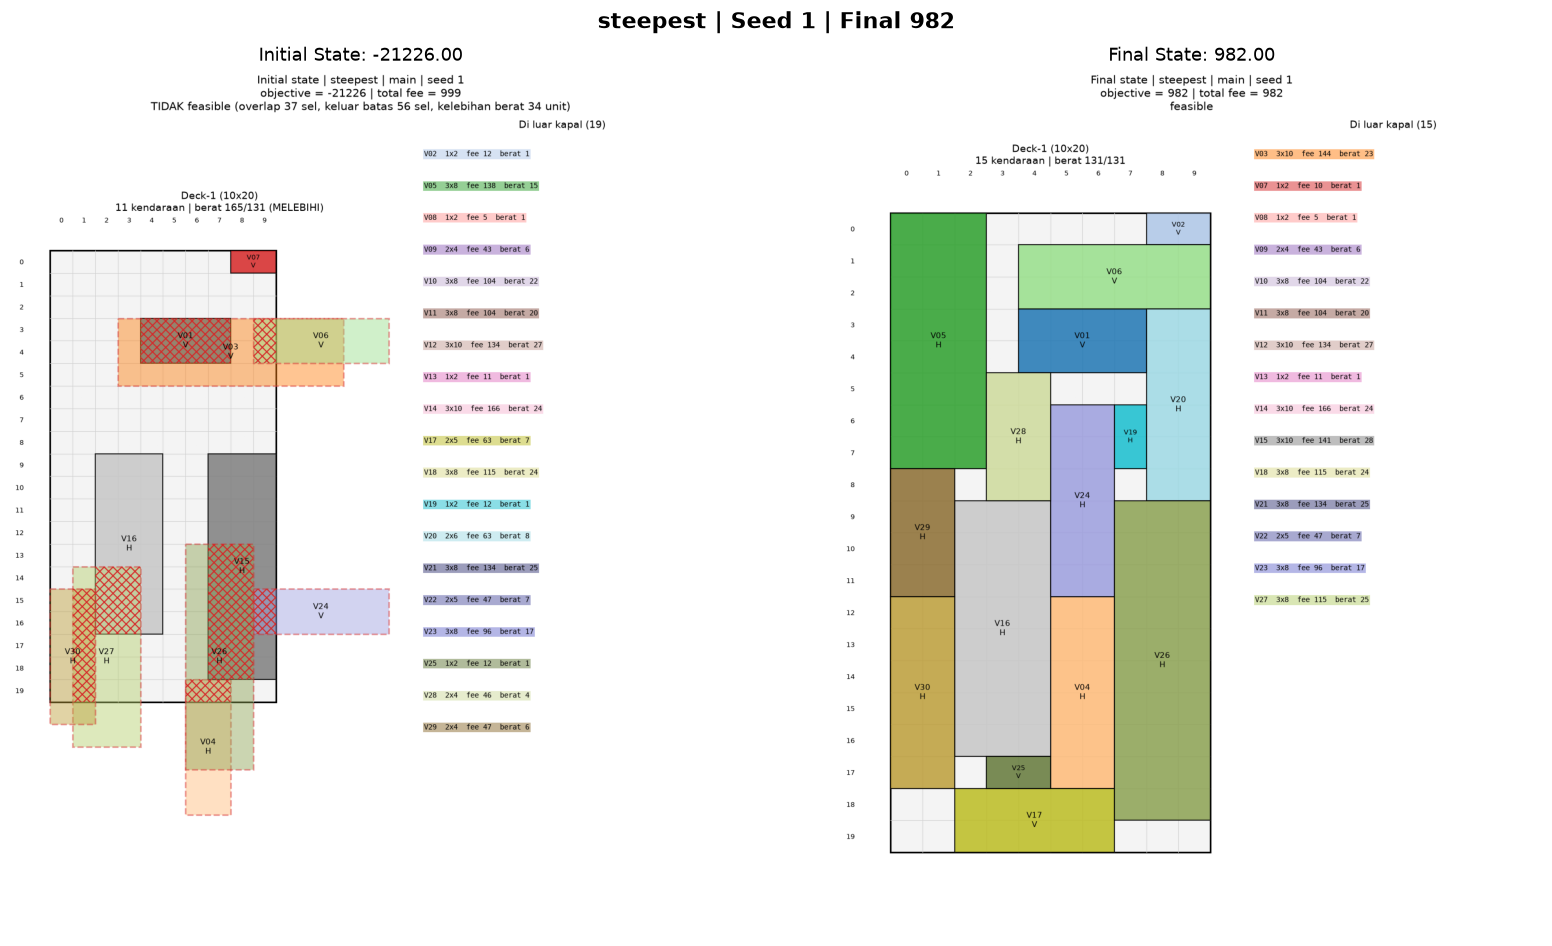

Gambar: output/analysis/09_states_steepest.png
Baseline kosong: False | Kandidat feasible ditemukan: True


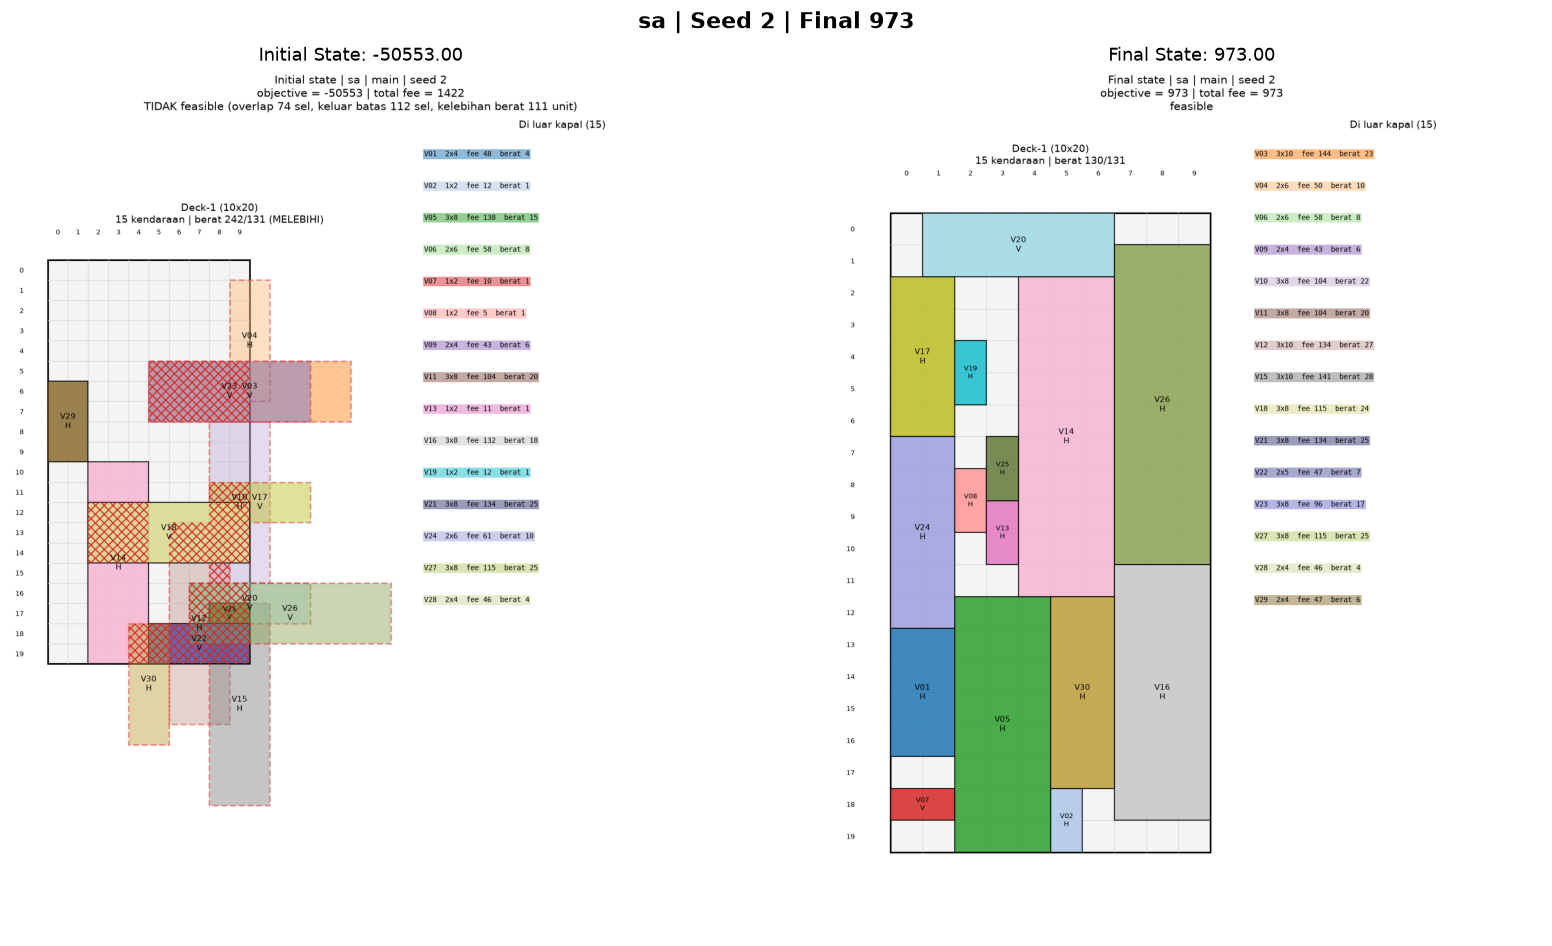

Gambar: output/analysis/09_states_sa.png
Baseline kosong: False | Kandidat feasible ditemukan: True


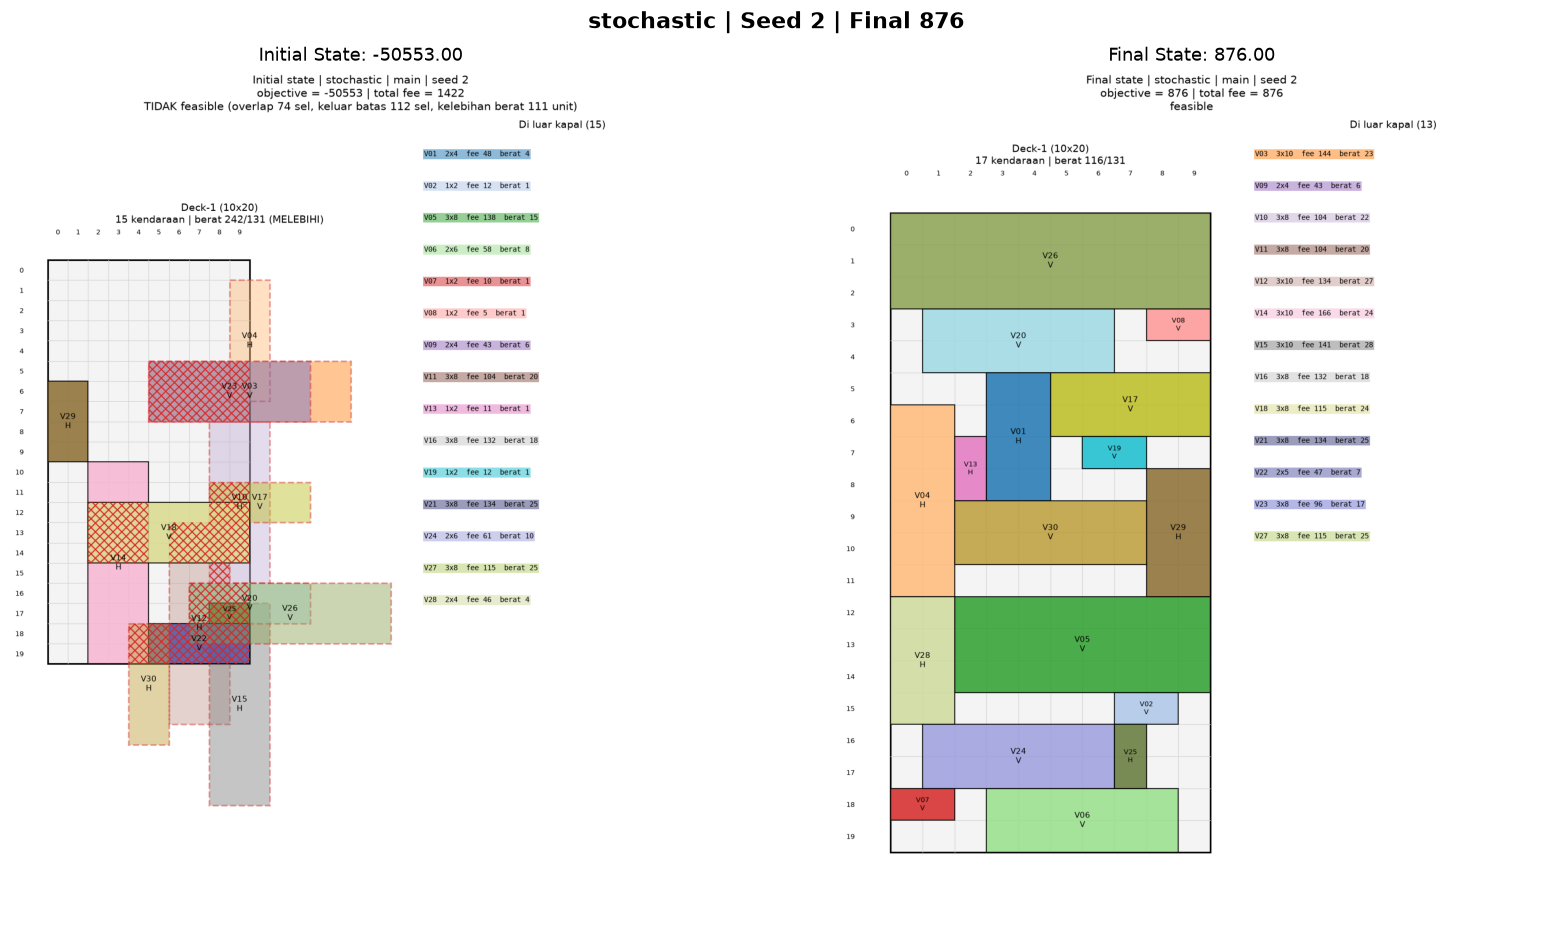

Gambar: output/analysis/09_states_stochastic.png
Baseline kosong: False | Kandidat feasible ditemukan: True


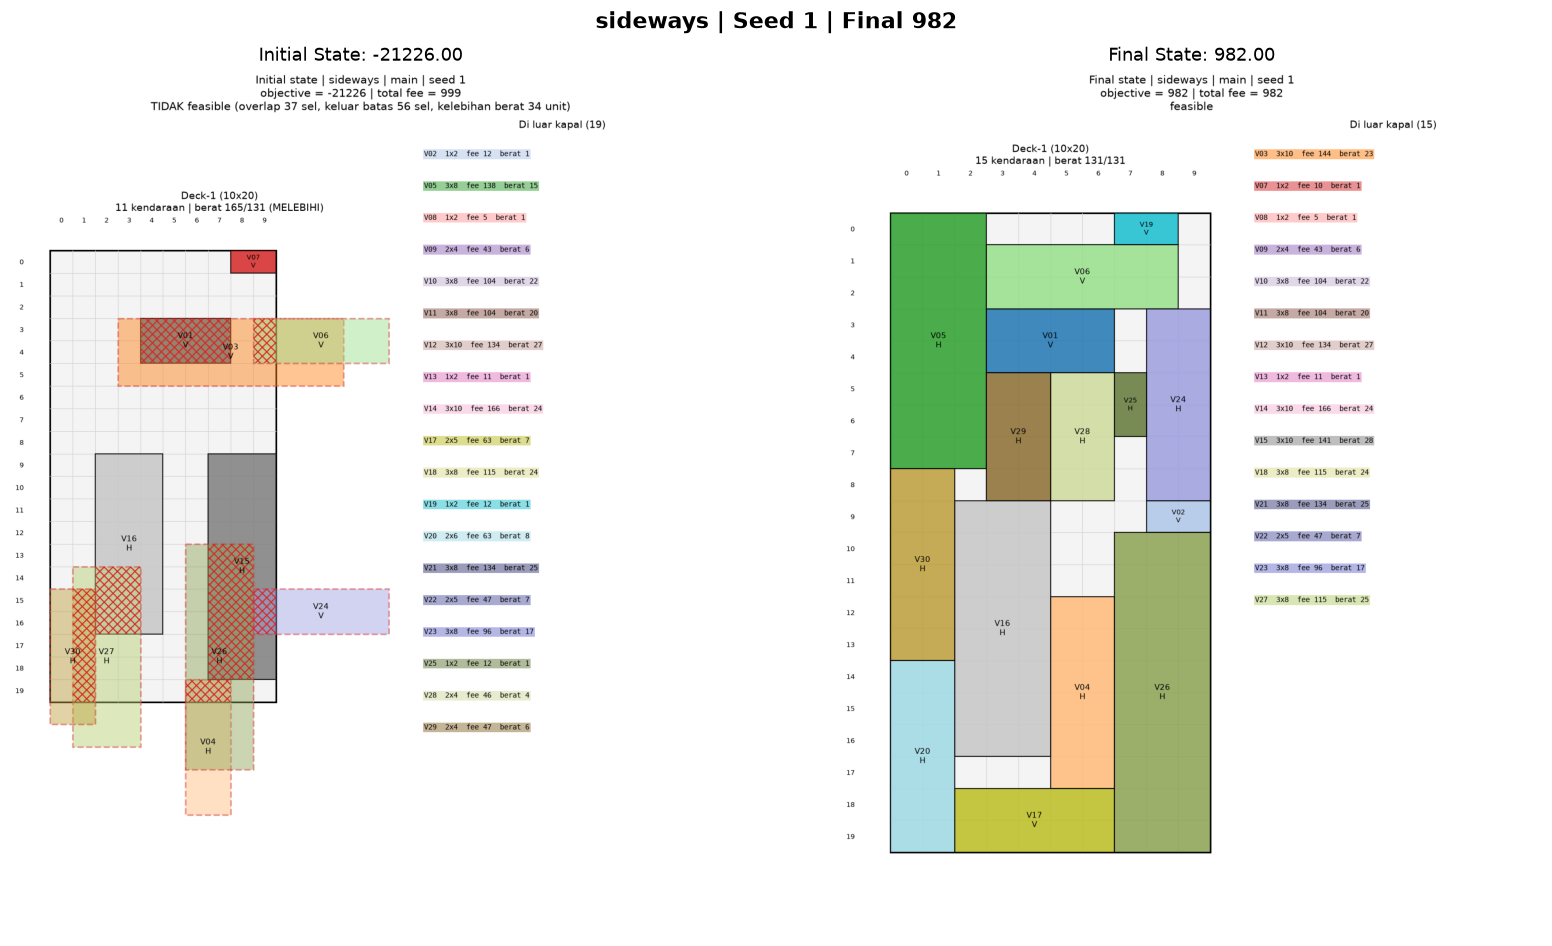

Gambar: output/analysis/09_states_sideways.png
Baseline kosong: False | Kandidat feasible ditemukan: True


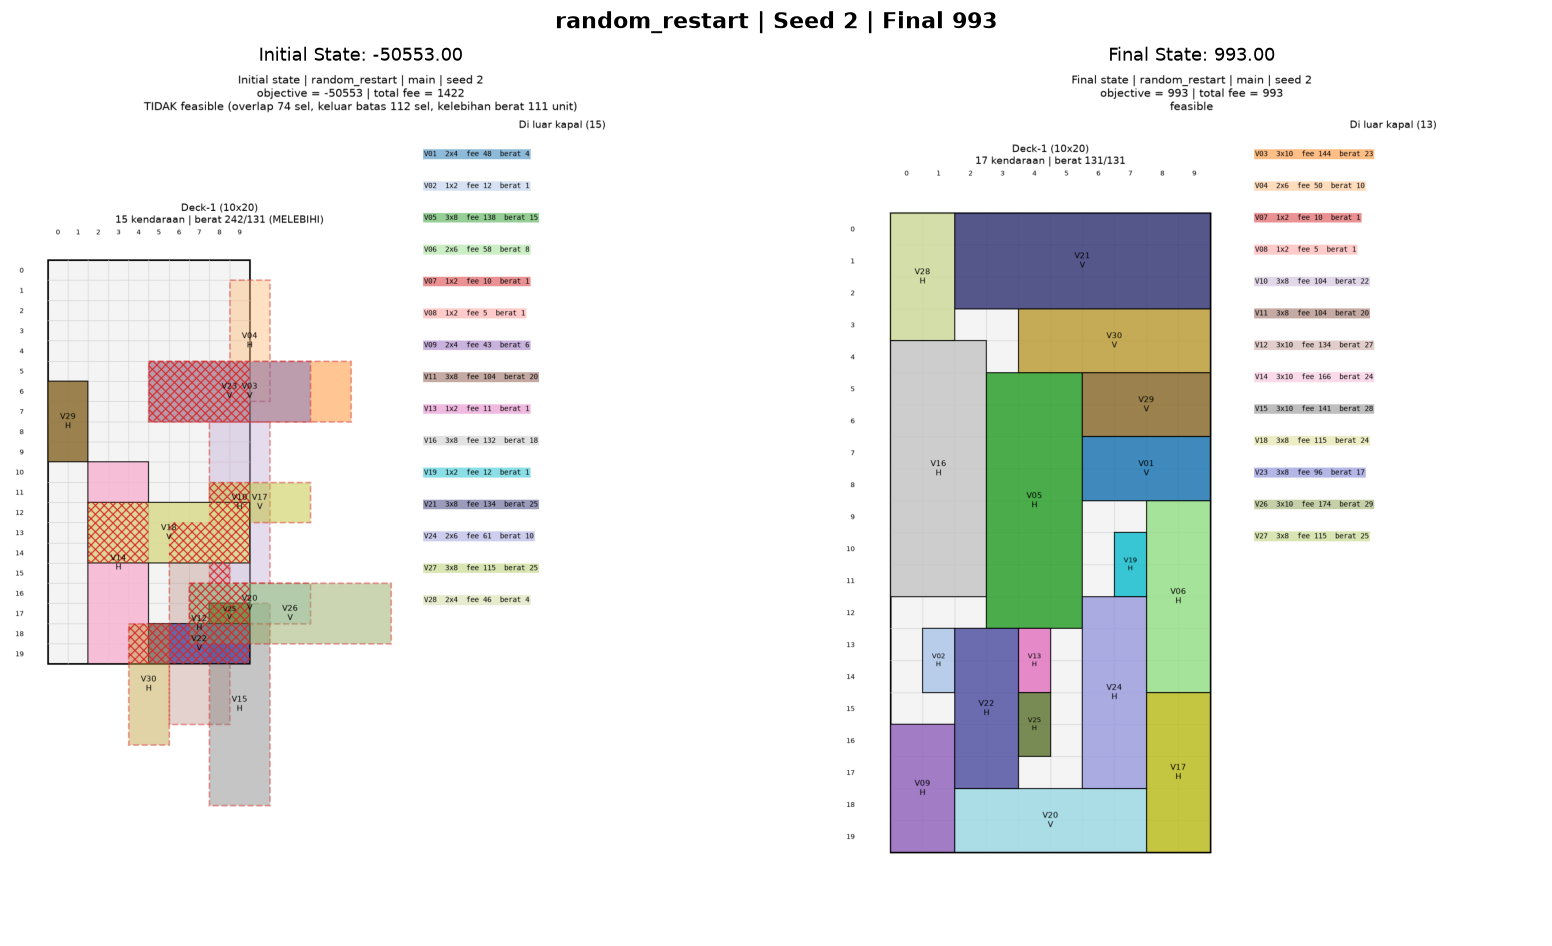

Gambar: output/analysis/09_states_random_restart.png
Baseline kosong: False | Kandidat feasible ditemukan: True


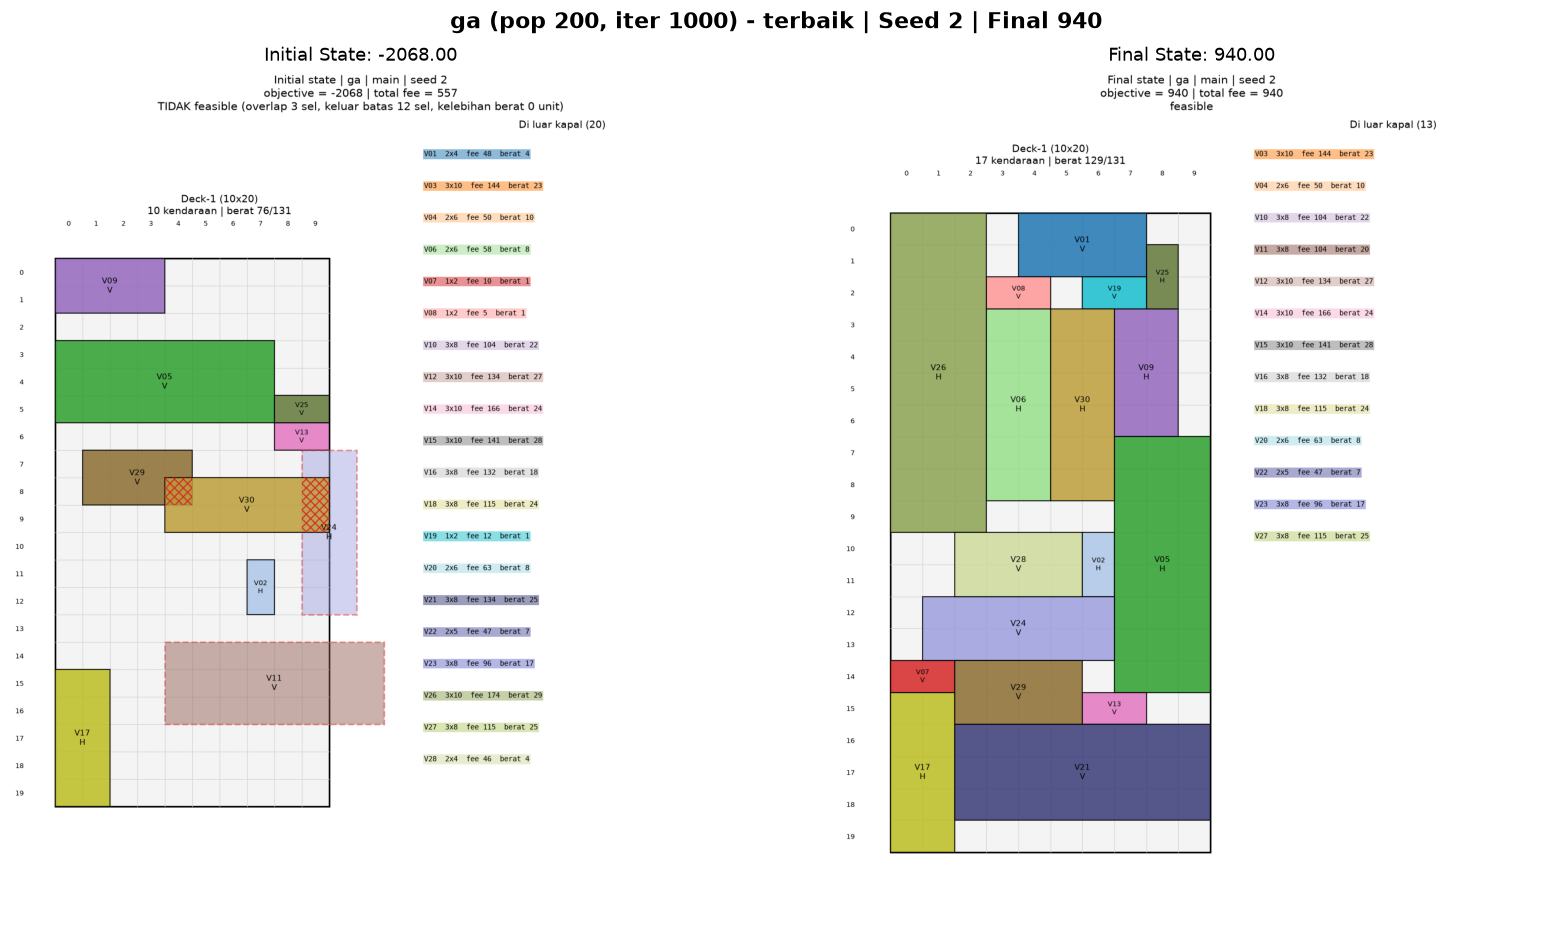

Gambar: output/analysis/09_states_ga.png
Baseline kosong: False | Kandidat feasible ditemukan: True


In [20]:
for label, results in compare.items():
    best = max(results, key=lambda result: result['final_objective'])
    run = next(run for run, result in pairs if result is best)
    path = run.path(CFG.EXPERIMENT_DIR)
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    for ax, stage, title in zip(axes, ('initial', 'final'), ('Initial State', 'Final State')):
        image_path = path.with_name(path.stem + f'_{stage}.png')
        ax.imshow(plt.imread(image_path))
        ax.set_title(f"{title}: {best[stage + '_objective']:.2f}", fontsize=11)
        ax.axis('off')
    fig.suptitle(f"{label} | Seed {run.seed} | Final {best['final_objective']:g}", fontsize=13, fontweight='bold')
    plt.tight_layout()
    show(fig, f'09_states_{run.algo}.png')
    print('Baseline kosong:', best['extra']['empty_baseline_used'], '| Kandidat feasible ditemukan:', best['extra']['found_feasible'])

> ### Insights
> Kualitas solusi dibaca dari fee dan feasibility, bukan hanya tampilan geladak yang rapat. Area kosong dapat muncul akibat kombinasi bentuk kendaraan dan kapasitas berat; gambar saja tidak memisahkan penyebab keduanya.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Multi-kapal dan Objective ETA <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Dua perluasan diuji tanpa mengubah variabel dasar persoalan: armada dengan beberapa kapal dan objective yang memberi bobot tambahan pada kendaraan ber-ETA kecil. Kedua eksperimen memakai kelompok hasil yang terpisah dari perbandingan utama.

---

## Penataan Armada

Objective armada menjumlahkan fee seluruh kapal, tetapi overlap dan kapasitas tetap diperiksa per geladak. Tabel berikut menampilkan pemanfaatan tiap kapal pada run multi-kapal dengan objective akhir tertinggi.

Kapal,Kendaraan,Berat,Kapasitas,Sel terisi,Luas
Deck-1,10,70.0,80,96,120
Deck-2,6,51.0,54,64,80
Deck-3,5,30.0,32,44,48


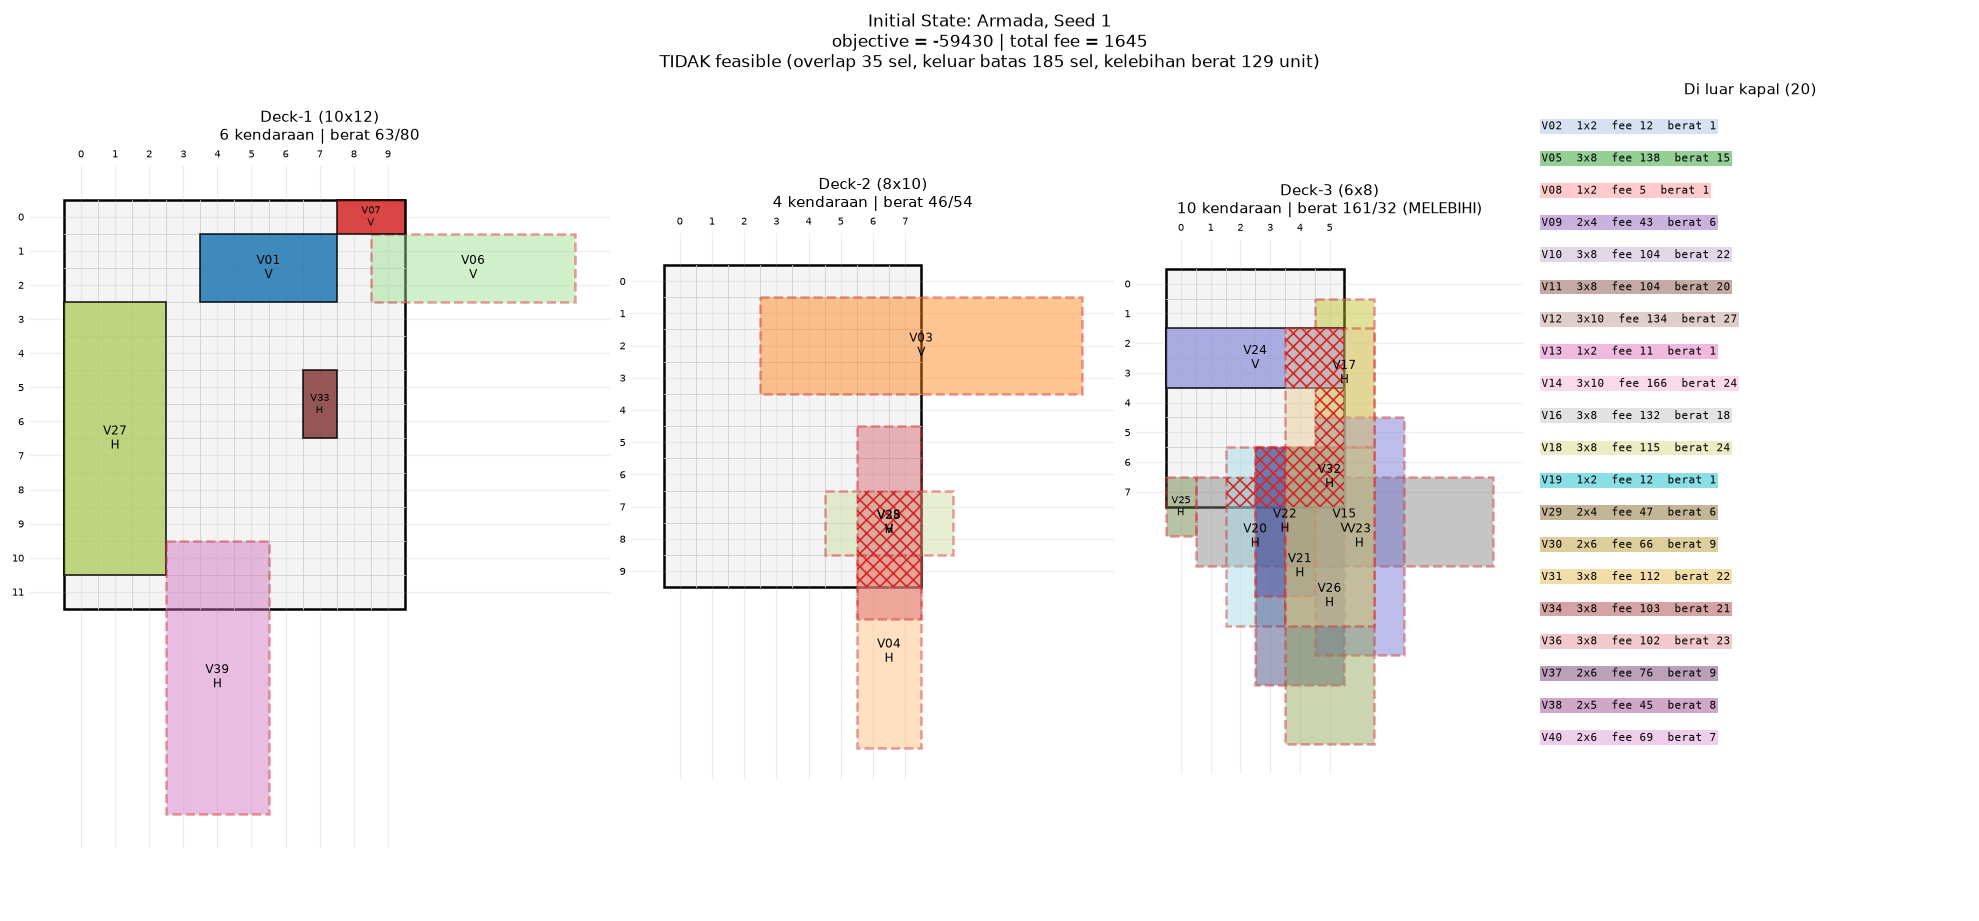

Gambar: output/analysis/10_fleet_initial.png


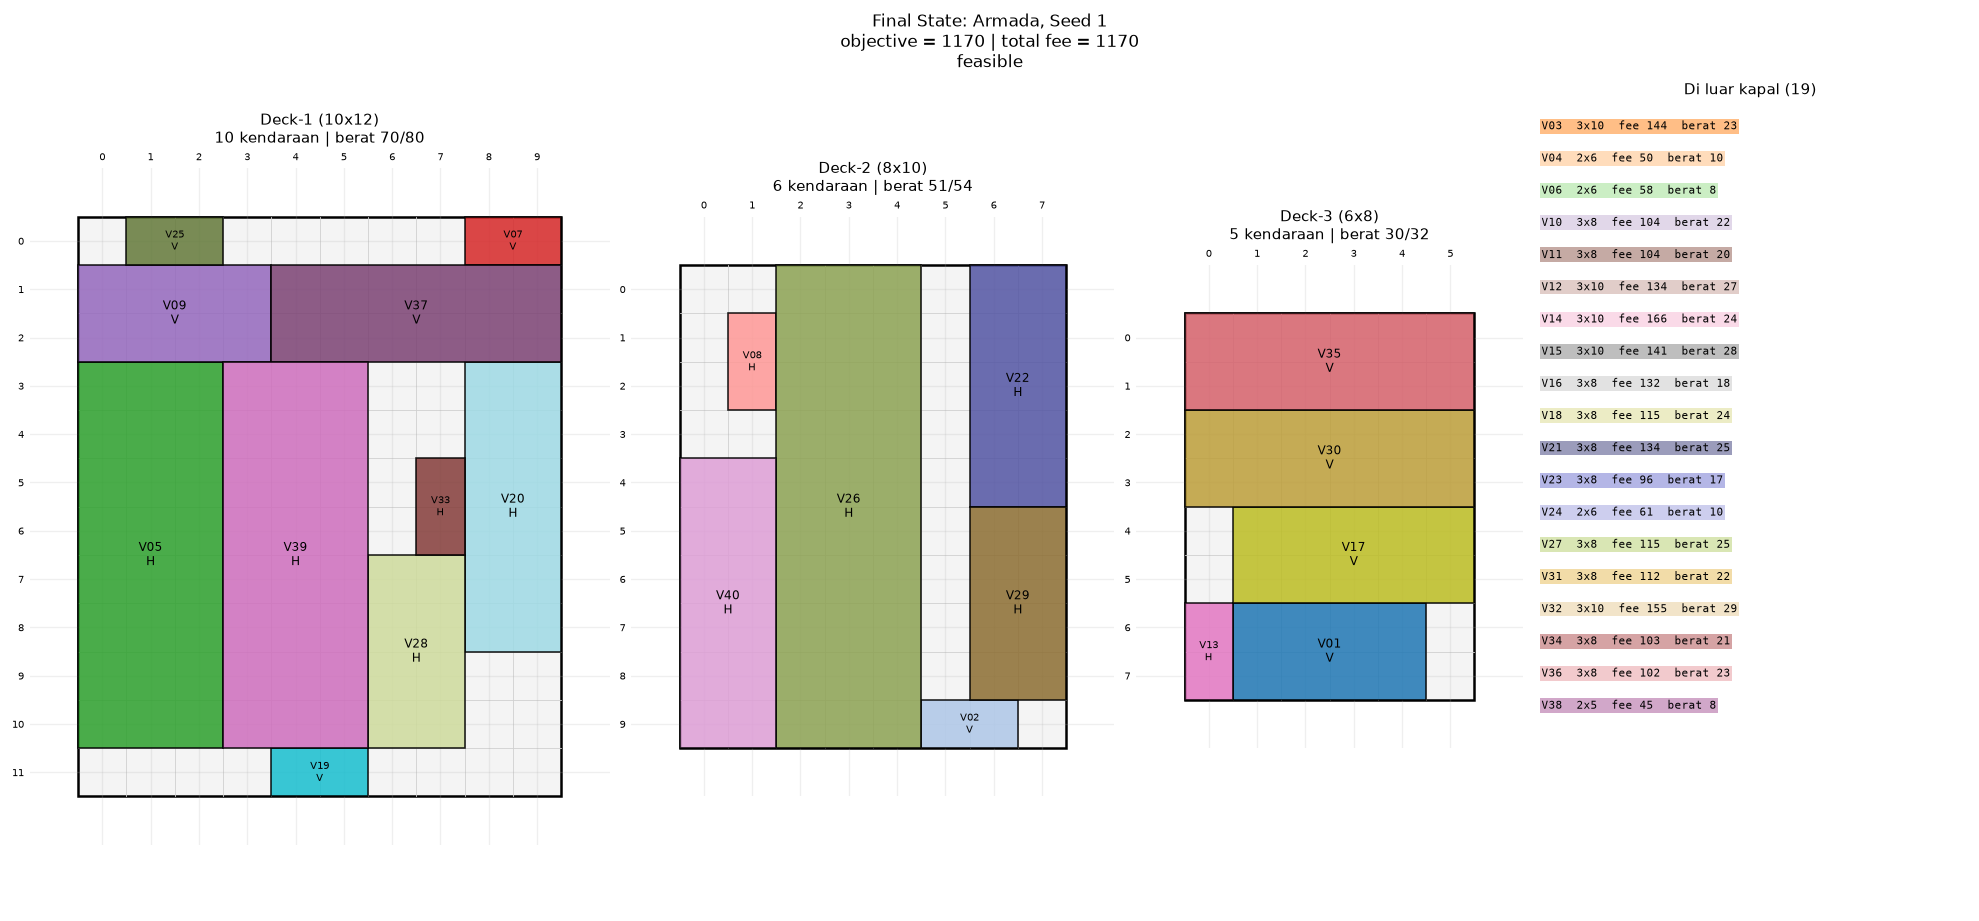

Gambar: output/analysis/10_fleet_final.png


> ### Insights
> Run multi terbaik memuat 21 kendaraan pada 3 kapal dengan objective 1170.00. Nilainya tidak dibandingkan langsung dengan instance satu kapal karena kandidat dan kapasitasnya berbeda.

In [21]:
multi_run, multi_best = max(of('multi'), key=lambda pair: pair[1]['final_objective'])
multi_problem = problems[multi_run.instance]
multi_state = State.from_dict(multi_problem, multi_best['final_state'])
evaluation = multi_state.evaluate()
table(['Kapal', 'Kendaraan', 'Berat', 'Kapasitas', 'Sel terisi', 'Luas'],
      [[ship.id, sum(p is not None and p[0] == index for p in multi_state.positions),
        evaluation.used_weight[index], ship.max_capacity, evaluation.occupied_cells[index], ship.area]
       for index, ship in enumerate(multi_problem.ships)])

for stage, title in (('initial', 'Initial State'), ('final', 'Final State')):
    fig = draw_state(multi_problem, multi_best[stage + '_state'], title=f'{title}: Armada, Seed {multi_run.seed}')
    show(fig, f'10_fleet_{stage}.png')

insights(f"Run multi terbaik memuat {multi_best['loaded']} kendaraan pada {len(multi_problem.ships)} kapal "
         f"dengan objective {multi_best['final_objective']:.2f}. "
         'Nilainya tidak dibandingkan langsung dengan instance satu kapal karena kandidat dan kapasitasnya berbeda.')

---

## Objective Berbasis Urgensi ETA

Objective alternatif menggunakan `fee * (1 + 1/(eta + 1))`. Bobot urgensi bukan pendapatan uang. Pasangan run fee dan ETA pada seed yang sama dievaluasi kembali dengan kedua ukuran agar perubahan prioritas dapat dibaca dengan benar.

In [22]:
eta_rows = []
for eta_run, eta_result in of('eta'):
    original = problems[eta_run.instance]
    fee_run, fee_result = next((run, result) for run, result in of('sa') if run.seed == eta_run.seed)
    assert fee_run.instance == eta_run.instance
    assert fee_result['params'] == eta_result['params']
    assert State.from_dict(original, fee_result['initial_state']).positions == State.from_dict(original, eta_result['initial_state']).positions
    for mode, result in (('fee', fee_result), ('eta', eta_result)):
        state = State.from_dict(original, result['final_state'])
        loaded = [v for v, position in zip(original.vehicles, state.positions) if position is not None]
        revenue = shipping_fee_total(original, state.positions)
        urgency = sum(urgency_weight(vehicle) for vehicle in loaded)
        mean_eta = mean(vehicle.eta for vehicle in loaded) if loaded else None
        eta_rows.append([eta_run.seed, mode, revenue, urgency, len(loaded), mean_eta])
table(['Seed', 'Objective pencarian', 'Fee asli', 'Bobot urgensi', 'Dimuat', 'Mean ETA (hari)'],
      [[*row[:2], f'{row[2]:.2f}', f'{row[3]:.2f}', row[4], '-' if row[5] is None else f'{row[5]:.2f}'] for row in eta_rows])

fee_mean = mean(row[2] for row in eta_rows if row[1] == 'fee')
eta_fee_mean = mean(row[2] for row in eta_rows if row[1] == 'eta')
fee_urgency = mean(row[3] for row in eta_rows if row[1] == 'fee')
eta_urgency = mean(row[3] for row in eta_rows if row[1] == 'eta')
insights(f'Perubahan mean dari objective fee ke ETA: pendapatan asli {eta_fee_mean - fee_mean:+.2f}; '
         f'bobot urgensi {eta_urgency - fee_urgency:+.2f}. '
         'Penempatan awal dan parameter berpasangan; yang diubah adalah nilai yang dioptimasi.')

Seed,Objective pencarian,Fee asli,Bobot urgensi,Dimuat,Mean ETA (hari)
1,fee,964.00,1243.45,11,3.82
1,eta,984.00,1293.30,16,3.62
2,fee,973.00,1206.80,15,4.20
2,eta,941.00,1223.58,16,3.44
3,fee,962.00,1148.13,17,4.29
3,eta,941.00,1228.80,15,3.80


> ### Insights
> Perubahan mean dari objective fee ke ETA: pendapatan asli -11.00; bobot urgensi +49.10. Penempatan awal dan parameter berpasangan; yang diubah adalah nilai yang dioptimasi.

---

## Visualisasi Hasil ETA

Run ETA terbaik ditampilkan dengan label bobot urgensi dan fee asli secara terpisah. Nilai pendapatan dihitung dari kendaraan yang benar-benar dimuat menggunakan fee pada input asli.

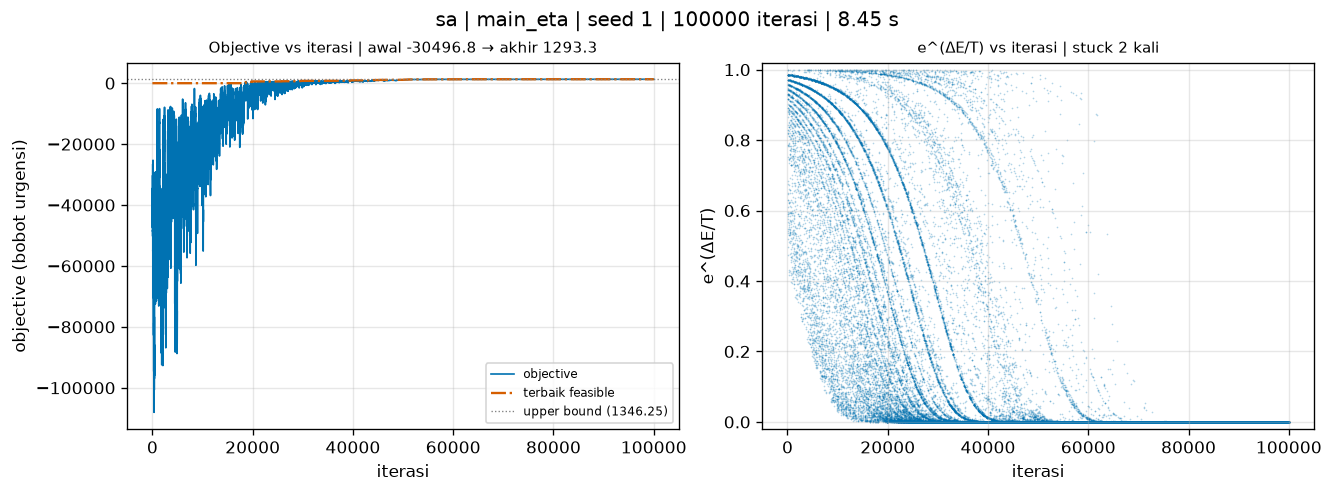

Gambar: output/analysis/11_eta_convergence.png


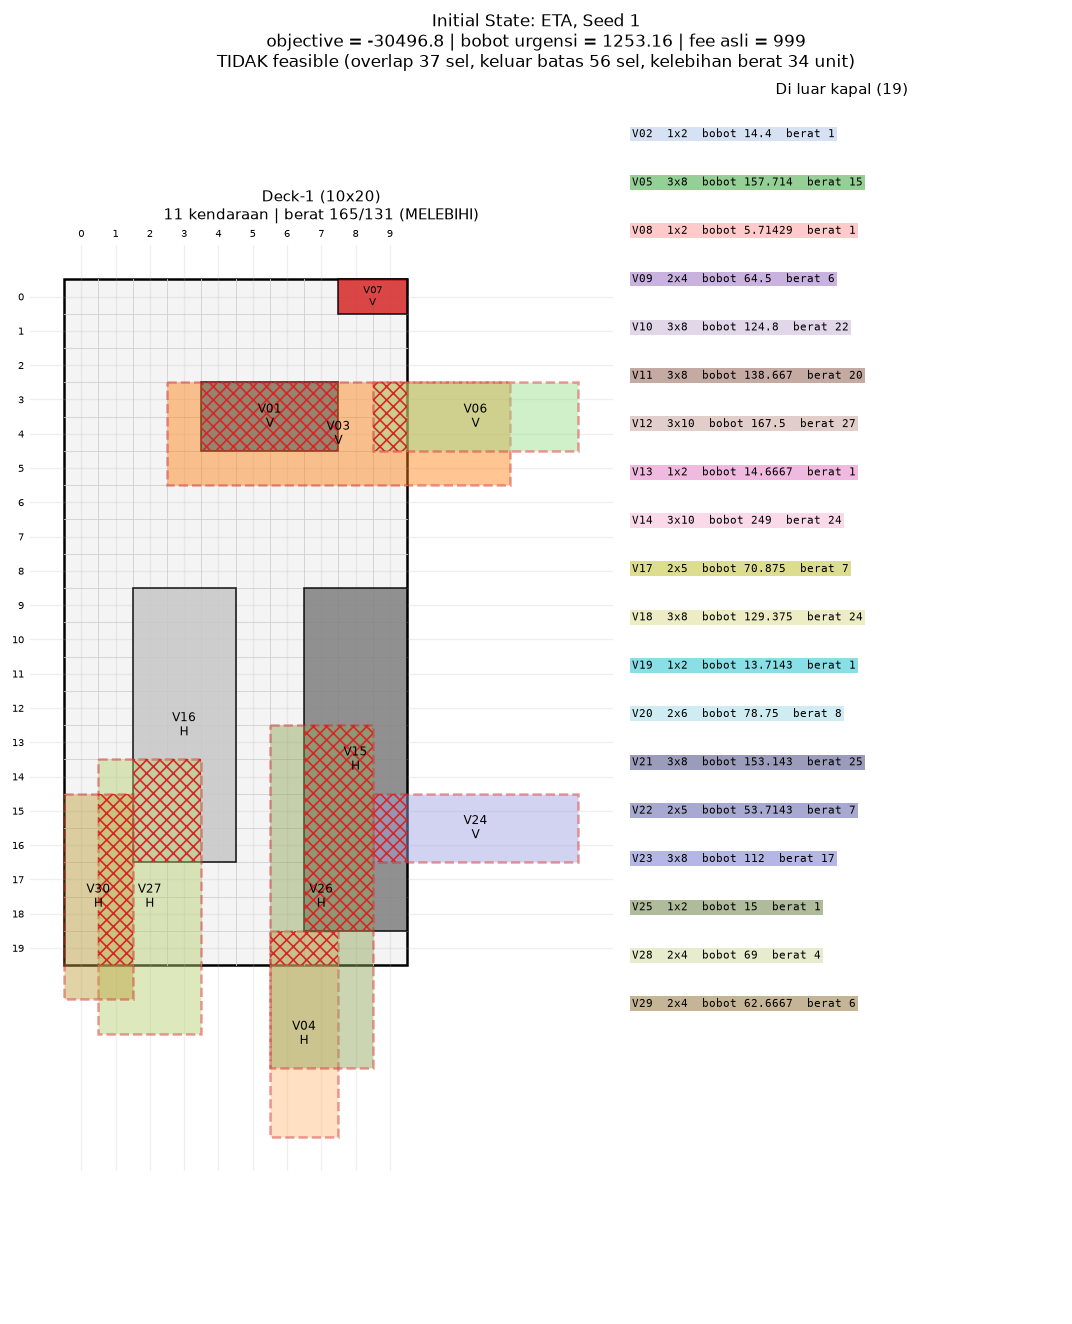

Gambar: output/analysis/11_eta_initial.png


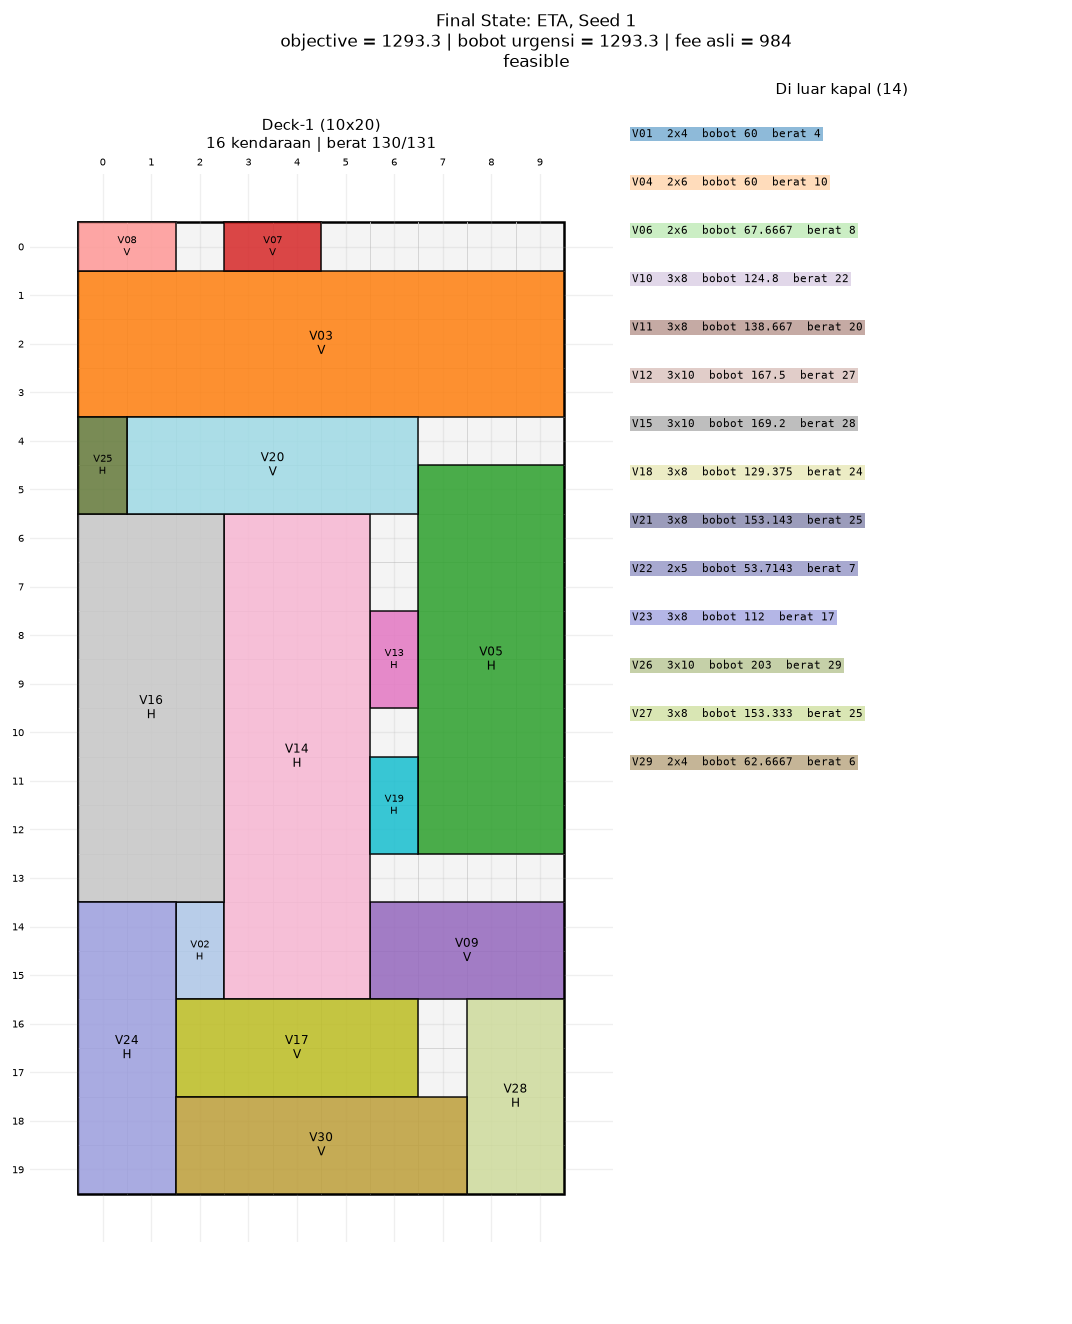

Gambar: output/analysis/11_eta_final.png


In [23]:
eta_run, eta_best = max(of('eta'), key=lambda pair: pair[1]['final_objective'])
original = problems[eta_run.instance]
transformed = eta_problem(original)
show(plot_run(eta_best), '11_eta_convergence.png')
for stage, title in (('initial', 'Initial State'), ('final', 'Final State')):
    state = State.from_dict(original, eta_best[stage + '_state'])
    fig = draw_state(transformed, eta_best[stage + '_state'], title=f'{title}: ETA, Seed {eta_run.seed}',
                     objective='eta', shipping_fee=shipping_fee_total(original, state.positions))
    show(fig, f'11_eta_{stage}.png')

> ### Insights
> Field `total_fee` pada JSON ETA berisi bobot transformasi. Pendapatan aslinya berada pada `extra.shipping_fee_total`; kedua istilah tersebut tidak dapat dipertukarkan ketika membahas keuntungan pengiriman.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Batas Atas dan Optimum Eksak <a name="11"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Relaksasi knapsack mengabaikan sebagian kendala geometri sehingga memberi upper bound. Instance kecil diselesaikan dengan branch-and-bound untuk menyediakan pembanding yang diketahui eksak.

---

## Verifikasi pada Instance Kecil

Nilai optimum dan susunan akhirnya dihitung langsung dari `small.json`. Pemeriksaan ini menunjukkan perbedaan antara batas atas dan optimum fisik; hasil instance kecil tidak membuktikan optimalitas pada instance utama.

Instance,Optimum eksak,Upper bound,Selisih UB
small,287.0,298.0,11.0


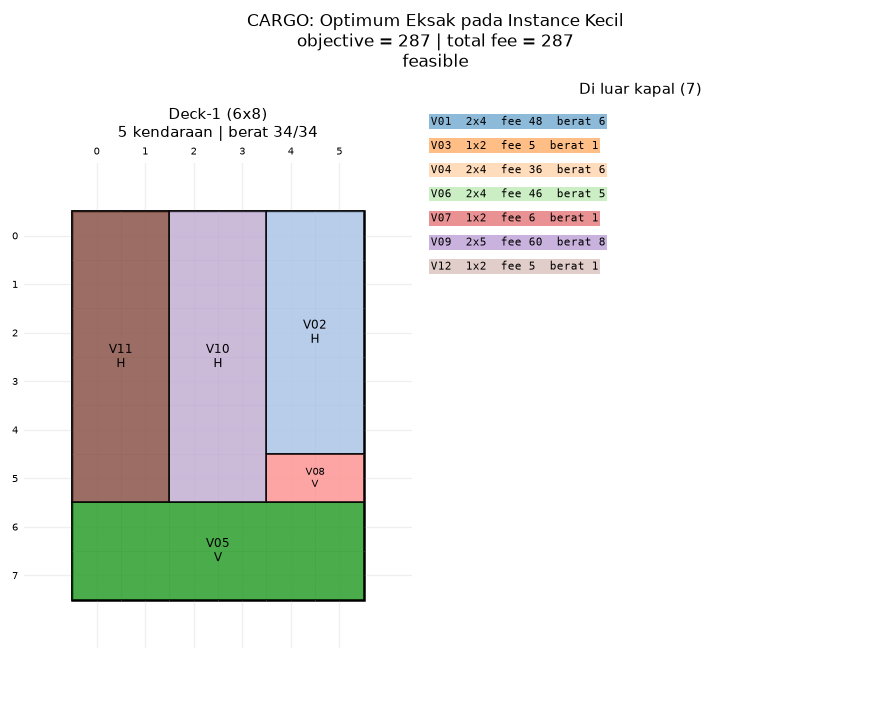

Gambar: output/analysis/12_exact_small.png


> ### Insights
> Instance kecil memiliki optimum 287 dan UB 298. Pada instance utama, solusi terbaik 993 dan UB 1035 membentuk batas bawah serta batas atas optimum. Sisa gap dapat berasal dari relaksasi yang longgar, pencarian yang belum optimal, atau keduanya.

In [24]:
small = load_problem(CFG.DATA_DIR / 'small.json')
exact = brute_force(small, max_nodes=CFG.EXACT_MAX_NODES)
small_bound = upper_bound(small)
assert exact.evaluate().is_feasible
assert exact.objective <= small_bound + 1e-7
table(['Instance', 'Optimum eksak', 'Upper bound', 'Selisih UB'],
      [[small.name, exact.objective, small_bound, small_bound - exact.objective]])
show(draw_state(small, exact.to_dict(), title='CARGO: Optimum Eksak pada Instance Kecil'), '12_exact_small.png')

main_bound = of('hc')[0][1]['upper_bound']
best_main = max(result['final_objective'] for results in compare.values() for result in results)
insights(f'Instance kecil memiliki optimum {exact.objective:g} dan UB {small_bound:g}. '
         f'Pada instance utama, solusi terbaik {best_main:g} dan UB {main_bound:g} membentuk batas bawah serta batas atas optimum. '
         + ('Solusi feasible telah mencapai UB sehingga optimalitas terbukti.'
            if math.isclose(best_main, main_bound, abs_tol=1e-7)
            else 'Sisa gap dapat berasal dari relaksasi yang longgar, pencarian yang belum optimal, atau keduanya.'))

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="12"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian akhir merangkum hasil kuantitatif serta batas interpretasi CARGO. Kesimpulan dibatasi pada instance, seed, dan budget yang dicatat dalam protokol.

---

## Ringkasan Temuan

Kualitas, kecepatan, dan konsistensi tidak harus menunjuk algoritma yang sama. Ringkasan berikut dihitung dari tabel perbandingan dan tidak menggunakan angka yang diketik ulang pada markdown.

In [25]:
insights(f'Pada {len(pairs)} run resmi, mean kualitas tertinggi pada instance utama dicapai {best_quality[0]}; '
         f'durasi mean terendah oleh {fastest[0]}; simpangan baku terendah oleh {consistent[0]}. '
         f'Mean episode stuck checkpoint SA = {mean(result["extra"]["stuck_count"] for result in sa_results):.2f}. '
         'Perbandingan budget GA serta pasangan objective ETA memperlihatkan bahwa pemilihan konfigurasi perlu mempertimbangkan kualitas dan biaya.')

> ### Insights
> Pada 39 run resmi, mean kualitas tertinggi pada instance utama dicapai random_restart; durasi mean terendah oleh stochastic; simpangan baku terendah oleh sa. Mean episode stuck checkpoint SA = 2.67. Perbandingan budget GA serta pasangan objective ETA memperlihatkan bahwa pemilihan konfigurasi perlu mempertimbangkan kualitas dan biaya.

### Kelebihan Pendekatan

Representasi koordinat eksplisit membuat posisi, orientasi, dan kendaraan yang tidak dimuat dapat diperiksa langsung. Evaluator bersama menjaga definisi kendala tetap konsisten pada semua algoritma, sementara delta evaluation mengurangi pekerjaan evaluasi neighborhood. Pemisahan search dan analisis memungkinkan tabel serta gambar dibuat ulang dari JSON yang sama.

---

### Keterbatasan yang Diketahui

Tiga seed memenuhi minimum eksperimen, tetapi belum cukup untuk klaim signifikansi statistik atau generalisasi ke semua input. Konfigurasi GA terbaik dipilih dari data eksperimen yang sama, bukan evaluasi hold-out. Monitoring SA hanya mengamati checkpoint dan menambah biaya yang sudah masuk durasi. Baseline kosong menjamin hasil fisik valid saat budget terlalu kecil, bukan keberhasilan menemukan muatan bernilai tinggi.

---

### Arah Pengembangan Berikutnya

Eksperimen lanjutan dapat memperluas variasi ukuran geladak, distribusi dimensi, dan jumlah seed. Ablasi operator crossover, mutasi, dan aturan proposal diperlukan sebelum menyimpulkan penyebab perbedaan kualitas. Untuk pelaporan saat ini, seluruh pembandingan tetap menggunakan konfigurasi resmi yang tercatat tanpa menambahkan hasil sintetis.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="13"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Tim Asisten Laboratorium Inteligensi Artifisial. (2026). *Spesifikasi Tugas Besar 1 IF3070 Dasar Inteligensi Artifisial 2026/2027*, versi 1.1. Dokumen tersedia pada direktori `docs/`.

Khodra, M. L. (2021). *Beyond Classical Search: Hill-Climbing Search*. [Video](https://www.youtube.com/watch?v=L0b0CN3Fds8).

Khodra, M. L. (2021). *Beyond Classical Search: Simulated Annealing*. [Video](https://www.youtube.com/watch?v=AdhG7HnhYrk).

Khodra, M. L. (2021). *Beyond Classical Search: Genetic Algorithm*. [Video](https://www.youtube.com/watch?v=aI41TGo9J9c).

Kelompok G09 - Sepakat. *Desain Implementasi dan Protokol Eksperimen CARGO*. [Desain](../docs/DESIGN.md), [Eksperimen](../docs/EXPERIMENTS.md).

Project Jupyter. *NBClient: Executing Notebooks*. [Dokumentasi](https://nbclient.readthedocs.io/en/latest/client.html).

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Thanks! <a name="thanks"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih kepada:**

Dosen pengampu dan tim asisten IF3070 yang menyusun persoalan serta spesifikasi tugas. Seluruh anggota **G09 - Sepakat** bertanggung jawab memahami, memeriksa, dan menjelaskan implementasi serta hasil CARGO.